# EDA — Chatbot con NLP para PQRS en salud con soporte en wayuunaiki básico y lenguaje simplificado

**Proyecto académico — Fase 1 · Grupo 07** (Camilo Mendoza, Alberto Fester)
**Notebook:** `EDA_PQRS_NLP.ipynb` · **Alcance:** análisis exploratorio de datos

> **Aviso de alcance y honestidad de los datos.** Este notebook trabaja con **dos tipos de fuentes que no deben mezclarse**:
> 1. **Corpus de traducción español–wayuunaiki** (repositorio `RLTranslator`): recurso de *referencia lingüística*. **No contiene PQRS etiquetadas**.
> 2. **Dataset sintético de PQRS** (ficticio, generado con plantillas): sirve para **demostrar técnicas de análisis** de clasificación de intenciones. **No representa la distribución de las PQRS reales** de ninguna institución de salud.
>
> Toda cifra del corpus se calcula a partir de los archivos cargados; si un archivo no está disponible, el notebook lo indica y **no inventa estadísticas**.

## Sección 1. Introducción

**Propósito.** Explorar las fuentes disponibles, verificar su calidad y establecer las bases para construir un dataset propio de clasificación de intenciones de PQRS (Peticiones, Quejas, Reclamos y Sugerencias) en el sector salud.

**Relación con el proyecto.** El chatbot deberá (a) reconocer la intención de mensajes escritos por personas con distintos niveles de alfabetización, (b) apoyarse, cuando sea posible, en vocabulario básico en wayuunaiki, y (c) escalar a un agente humano o priorizar urgencias. Antes de entrenar, el EDA permite saber qué datos existen, cuáles son confiables y qué falta.

**Preguntas que guían el análisis**

| # | Pregunta | Sección |
|---|----------|---------|
| P1 | ¿Qué contienen los archivos del corpus y del dataset sintético (tamaño, columnas, particiones)? | 3, 4 |
| P2 | ¿Qué tan limpios están: vacíos, duplicados, codificación, anomalías? | 5 |
| P3 | ¿Las líneas en español y wayuunaiki están alineadas y tienen longitudes coherentes? | 5, 6 |
| P4 | ¿Cómo se distribuyen las intenciones y los estilos en el dataset sintético? | 5, 7 |
| P5 | ¿Qué vocabulario caracteriza cada intención y qué intenciones podrían solaparse? | 8 |
| P6 | ¿Qué debe corregirse o ampliarse antes de entrenar un clasificador real? | 9 |

## Sección 2. Entorno de trabajo

Se usan principalmente `pandas`, `NumPy` y `Matplotlib` (`seaborn` es opcional). No se descargan modelos ni se ejecutan scripts de entrenamiento del repositorio. La semilla fija hace reproducible el dataset sintético y las particiones de demostración.

In [ ]:
# ============ Sección 2: entorno ============
import os, sys, re, csv, json, math, random, hashlib, platform, unicodedata, urllib.request, urllib.error
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

try:
    import seaborn as sns
    HAY_SEABORN = True
except ImportError:          # seaborn es opcional: el notebook funciona sin él
    HAY_SEABORN = False

# Compatibilidad: display/Markdown existen en Jupyter y Colab; en otros entornos se imprime texto.
try:
    from IPython.display import display, Markdown
except ImportError:
    def display(*objs):
        for o in objs:
            print(o.to_string() if hasattr(o, "to_string") else o)
    def Markdown(t):
        return t

def mostrar_md(texto):
    display(Markdown(texto))

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

EN_COLAB = "google.colab" in sys.modules

versiones = pd.DataFrame({
    "componente": ["Python", "pandas", "NumPy", "Matplotlib", "seaborn", "Colab", "Semilla"],
    "versión": [platform.python_version(), pd.__version__, np.__version__, matplotlib.__version__,
                sns.__version__ if HAY_SEABORN else "no instalado (opcional)","sí" if EN_COLAB else "no", SEMILLA]})
display(versiones)

,componente,versión
0,Python,3.13.18
1,pandas,2.2.3
2,NumPy,2.1.3
3,Matplotlib,3.10.0
4,seaborn,0.13.2
5,Colab,sí
6,Semilla,42


### Parámetros configurables y procedencia del corpus

**Procedencia y Citación (Verificada el 2025).**
- Repositorio Oficial: AmericasNLP 2025 Shared Task 1 - Machine Translation (<https://github.com/AmericasNLP/americasnlp2025/tree/main/ST1_MachineTranslation/data/wayuu-spanish>).
- **Referencia Bibliográfica Oficial:**
  > Prieto, J., Martinez, C., Robles, M., Moreno, A., Palacios, S., y Manrique, R. (2024). *Translation systems for low-resource Colombian Indigenous languages, a first step towards cultural preservation*. Proceedings of the 4th Workshop on Natural Language Processing for Indigenous Languages of the Americas, 7–14. <https://aclanthology.org/2024.americasnlp-1.2/>
- **Licencia:** No se identifica un archivo de licencia explícito en la carpeta de datos de AmericasNLP 2025. La ausencia de un archivo de licencia identificado no debe interpretarse como autorización irrestricta de redistribución de los datos.
- Estructura: Contiene archivos paralelos de oraciones en español (`.es`), wayuunaiki (`.guc`) y metadatos de procedencia (`.source`) para las particiones `train` y `dev`.

Cada archivo cargado queda registrado con su tamaño y huella **SHA-256**, de modo que el informe pueda citar exactamente la versión analizada.

In [39]:
# ============ Parámetros (modificables) ============
REPO_DIR   = Path(os.environ.get("EDA_REPO_DIR", "americasnlp_wayuu"))  # Carpeta local para los archivos del corpus
MANUAL_DIR = Path("datos_manuales")                                     # Alternativa local manual
DATA_DIR   = Path("data")                                               # Dataset sintético
OUT_DIR    = Path("salidas_eda")                                        # Figuras y evidencias
INTENTAR_DESCARGA = os.environ.get("EDA_DESCARGAR", "1") == "1"
SUBIR_MANUAL_COLAB = False

# URL base de descarga directa desde el repositorio de AmericasNLP 2025
RAW_BASE = "https://raw.githubusercontent.com/AmericasNLP/americasnlp2025/main/ST1_MachineTranslation/data/wayuu-spanish/"

ARCHIVOS_CORPUS = {
    "train.es":      "train.es",
    "train.guc":     "train.guc",
    "train.source":  "train.source",
    "dev.es":        "dev.es",
    "dev.guc":       "dev.guc",
    "dev.source":    "dev.source",
    "diccionario":   "assets/spanish_to_wayuunaiki_short.csv", # Mantenemos diccionario como referencia si está disponible
}

ENCABEZADOS_CONOCIDOS = {"es", "guc", "text", "texto", "spanish", "wayuu", "wayuunaiki", "source", "target",
                         "spanish_text", "wayuu_text", "sentence", "translation", "español", "espanol"}

for d in (DATA_DIR, OUT_DIR, REPO_DIR, MANUAL_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Directorio de trabajo:", Path.cwd())
print("Corpus esperado en  :", REPO_DIR.resolve())


Directorio de trabajo: /content
Corpus esperado en  : /content/americasnlp_wayuu


## Sección 3. Carga de datos

**Estrategia de carga (en este orden):** (1) archivo local en `REPO_DIR/...`; (2) archivo en `datos_manuales/` con el mismo nombre; (3) descarga puntual desde GitHub *raw* si hay Internet; (4) si todo falla, **mensaje informativo con instrucciones** y el análisis continúa con lo disponible. Los errores nunca se silencian.

**Si no hay conexión:** descargue manualmente los 5 archivos desde el repositorio (botón *Raw* → guardar como) y cópielos a `datos_manuales/` (local) o súbalos al panel *Archivos* de Colab dentro de esa carpeta. También puede poner `SUBIR_MANUAL_COLAB = True` en la celda de parámetros.

In [40]:
# ============ Sección 3a: localizar o descargar archivos del corpus ============
def sha256_de(ruta):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

def localizar_archivo(nombre, ruta_rel):
    candidatos = [REPO_DIR / Path(ruta_rel).name, MANUAL_DIR / Path(ruta_rel).name]
    for c in candidatos:
        if c.is_file():
            return c, "local", ""
    if INTENTAR_DESCARGA:
        destino = REPO_DIR / Path(ruta_rel).name
        try:
            destino.parent.mkdir(parents=True, exist_ok=True)
            # Si es el diccionario opcional, usamos la URL vieja; si no, la de AmericasNLP
            url = RAW_BASE + ruta_rel if nombre != "diccionario" else "https://raw.githubusercontent.com/Manuel-2011/RLTranslator/main/assets/spanish_to_wayuunaiki_short.csv"
            req = urllib.request.Request(url, headers={"User-Agent": "eda-pqrs-academico"})
            with urllib.request.urlopen(req, timeout=20) as r:
                datos = r.read()
            destino.write_bytes(datos)
            return destino, "descargado", ""
        except (urllib.error.URLError, TimeoutError, OSError) as e:
            return None, "no disponible", f"descarga fallida ({type(e).__name__}: {str(e)[:90]})"
    return None, "no disponible", "descarga desactivada y archivo no encontrado"

if SUBIR_MANUAL_COLAB and EN_COLAB:
    from google.colab import files
    MANUAL_DIR.mkdir(exist_ok=True)
    for n_arch, contenido in files.upload().items():
        (MANUAL_DIR / n_arch).write_bytes(contenido)

registro = []
RUTAS = {}
for nombre, rel in ARCHIVOS_CORPUS.items():
    ruta, estado, msg = localizar_archivo(nombre, rel)
    RUTAS[nombre] = ruta
    registro.append({"archivo": nombre, "ruta_repositorio": rel,
                     "estado": estado, "ruta_local": str(ruta) if ruta else "-",
                     "bytes": ruta.stat().st_size if ruta else None,
                     "sha256": sha256_de(ruta)[:16] + "…" if ruta else "-", "detalle": msg})
df_registro = pd.DataFrame(registro)
display(df_registro)

faltantes = [n for n, r in RUTAS.items() if r is None and n != "diccionario"]
if faltantes:
    print("\n⚠ ARCHIVOS NO DISPONIBLES:", ", ".join(faltantes))
    print("  → Copie esos archivos a:", MANUAL_DIR.resolve())
    print("  → Las secciones que dependen de ellos se omitirán con aviso; no se inventarán datos.")
CORPUS_OK = all(RUTAS[k] is not None for k in ("train.es", "train.guc", "train.source", "dev.es", "dev.guc", "dev.source"))
DICC_OK = RUTAS["diccionario"] is not None
print(f"\nCORPUS_OK (6 archivos paralelos de AmericasNLP) = {CORPUS_OK} | DICC_OK = {DICC_OK}")


,archivo,ruta_repositorio,estado,ruta_local,bytes,sha256,detalle
0,train.es,train.es,descargado,americasnlp_wayuu/train.es,4606449,ecd42ca6f59d654f…,
1,train.guc,train.guc,descargado,americasnlp_wayuu/train.guc,5753101,8fad6df8f5eec364…,
2,train.source,train.source,descargado,americasnlp_wayuu/train.source,624913,716711d55b958110…,
3,dev.es,dev.es,descargado,americasnlp_wayuu/dev.es,508303,ce4c9739dccbc5ab…,
4,dev.guc,dev.guc,descargado,americasnlp_wayuu/dev.guc,637148,3cfbb4838604c641…,
5,dev.source,dev.source,descargado,americasnlp_wayuu/dev.source,69354,21c7c8243ce89884…,
6,diccionario,assets/spanish_to_wayuunaiki_short.csv,descargado,americasnlp_wayuu/spanish_to_wayuunaiki_short.csv,1261534,9a84c351c041c090…,



CORPUS_OK (6 archivos paralelos de AmericasNLP) = True | DICC_OK = True


In [41]:
# ============ Sección 3b: lectura robusta de líneas (corpus paralelos) ============
def desescapar_csv(linea):
    s = linea.strip()
    if len(s) >= 2 and s[0] == '"' and s[-1] == '"':
        return s[1:-1].replace('""', '"'), True
    return linea, False

def leer_lineas(ruta):
    raw = Path(ruta).read_bytes()
    info = {"bytes": len(raw), "bom_utf8": raw.startswith(b"\xef\xbb\xbf"),
            "saltos_crlf": raw.count(b"\r\n"), "codificacion": "utf-8", "error_decodificacion": ""}
    try:
        txt = raw.decode("utf-8-sig")
    except UnicodeDecodeError as e:
        info["codificacion"] = "utf-8 con reemplazos ()"
        info["error_decodificacion"] = str(e)[:120]
        txt = raw.decode("utf-8", errors="replace")
    lineas = txt.split("\n")
    if lineas and lineas[-1] == "":
        lineas = lineas[:-1]
    return [l.rstrip("\r") for l in lineas], info

corpus_filas, info_archivos = [], {}
if CORPUS_OK:
    # Cargamos las extensiones .es, .guc y .source para cada partición
    for part in ("train", "dev"):
        for idioma in ("es", "guc", "source"):
            nombre = f"{part}.{idioma}"
            try:
                lineas, info = leer_lineas(RUTAS[nombre])
            except OSError as e:
                print(f"✗ Error leyendo {nombre}: {e}")
                CORPUS_OK = False
                break
            info_archivos[nombre] = info
            for i, l in enumerate(lineas, start=1):
                texto, entrecomillada = desescapar_csv(l)
                corpus_filas.append({"particion": part, "idioma": idioma, "linea": i,
                                     "texto": texto, "entrecomillada": entrecomillada,
                                     "posible_encabezado": (i == 1 and texto.strip().lower() in ENCABEZADOS_CONOCIDOS)})

if CORPUS_OK:
    df_corpus = pd.DataFrame(corpus_filas)
    df_corpus["texto_vacio"] = df_corpus["texto"].str.strip() == ""
    print(f"Corpus AmericasNLP cargado: {len(df_corpus):,} líneas en 6 archivos.")
    display(pd.DataFrame(info_archivos).T)
else:
    df_corpus = pd.DataFrame()
    print("Corpus no cargado: las secciones del corpus se omitirán con aviso.")


Corpus AmericasNLP cargado: 199,050 líneas en 6 archivos.


,bytes,bom_utf8,saltos_crlf,codificacion,error_decodificacion
train.es,4606449,False,0,utf-8,
train.guc,5753101,False,0,utf-8,
train.source,624913,False,0,utf-8,
dev.es,508303,False,0,utf-8,
dev.guc,637148,False,0,utf-8,
dev.source,69354,False,0,utf-8,


In [ ]:
# ============ Sección 3c: diccionario bilingüe (estructura desconocida a priori) ============
df_dicc = None
info_dicc = {}
if DICC_OK:
    try:
        lineas_d, info_dicc = leer_lineas(RUTAS["diccionario"])
        muestra = "\n".join(lineas_d[:50])
        try:
            dialecto = csv.Sniffer().sniff(muestra, delimiters=",;\t|")
            sep = dialecto.delimiter
        except csv.Error:
            sep = ","
        df_dicc = pd.read_csv(RUTAS["diccionario"], sep=sep, dtype=str, keep_default_na=False,
                              encoding="utf-8-sig", engine="python", on_bad_lines="warn")
        info_dicc["separador_detectado"] = repr(sep)
        print(f"Diccionario leído: {df_dicc.shape[0]:,} filas × {df_dicc.shape[1]} columnas; separador {sep!r}")
        print("Columnas:", list(df_dicc.columns))
    except Exception as e:                       # el diccionario es opcional: se informa y se sigue
        print(f"✗ No se pudo interpretar el diccionario ({type(e).__name__}: {e}). Se omite su análisis.")
        df_dicc = None
else:
    print("Diccionario no disponible: se omite su análisis.")

Diccionario leído: 29,246 filas × 2 columnas; separador ','
Columnas: ['spa', 'guc']


### Dataset sintético de PQRS (ficticio)

Se genera con plantillas escritas a mano (5 por combinación *intención × estilo*) más variaciones leves de cortesía y ortografía. Decisiones de diseño:

- **16 intenciones** exigidas por el proyecto; **3 estilos**: `formal`, `coloquial`, `simplificado` (frases cortas, vocabulario básico).
- **Sin datos personales**: no hay nombres, documentos, teléfonos ni radicados reales.
- **Sin wayuunaiki inventado**: todos los textos están en español (`language = es`). La columna `wayuu_status` deja explícito que el contenido en wayuunaiki está *pendiente de validación por hablantes competentes*.
- **Partición por plantilla** (`split`, `template_id`): todas las variantes de una misma plantilla van a la misma partición, para evitar fuga entre entrenamiento, validación y prueba. En la Sección 5 se mide qué pasaría con una partición aleatoria ingenua.
- Campos: `id, text, intent, language, style, source, template_id, split, safety_flags, review_status, wayuu_status`.

In [ ]:
# ---------------------------------------------------------------
# Generador del dataset SINTETICO de PQRS (datos ficticios).
# Reproducible: misma semilla -> mismo CSV.
# No contiene datos personales ni texto en wayuunaiki.
# ---------------------------------------------------------------
import random
import pandas as pd

INTENCIONES = [
    "consultar_cita", "solicitar_cita", "cancelar_cita", "medicamentos",
    "autorizacion", "queja_atencion", "reclamo_demora", "peticion_informacion",
    "sugerencia", "estado_pqrs", "saludo", "despedida",
    "urgencia_medica", "hablar_agente", "fuera_de_alcance", "no_entendido",
]
ESTILOS = ["formal", "coloquial", "simplificado"]

# Cinco plantillas base por (intencion, estilo). Texto ficticio escrito a mano.
PLANTILLAS = {
 "consultar_cita": {
  "formal": ["Quisiera consultar la fecha y hora de mi cita médica asignada.",
             "Solicito verificar cuándo está programada mi cita con medicina general.",
             "¿Me puede confirmar el horario de mi cita con el especialista?",
             "Necesito saber en qué sede y a qué hora es mi cita.",
             "Deseo conocer si mi cita del próximo mes sigue programada."],
  "coloquial": ["¿A qué hora era mi cita?",
                "¿Me recuerda cuándo me tocaba el control?",
                "No me acuerdo de la fecha de mi cita, ¿me ayuda?",
                "¿Todavía tengo cita con el doctor esta semana?",
                "¿Dónde me toca la cita?"],
  "simplificado": ["¿Cuándo es mi cita?", "Quiero saber la hora de mi cita.",
                   "¿Dónde es mi cita?", "Mi cita, ¿qué día es?", "Dime la fecha de mi cita."]},
 "solicitar_cita": {
  "formal": ["Deseo solicitar una cita de medicina general lo antes posible.",
             "Requiero agendar una cita con pediatría para mi hijo.",
             "Quisiera programar una cita con el odontólogo.",
             "Solicito una cita con ginecología en la sede principal.",
             "Necesito la asignación de una cita para un control médico."],
  "coloquial": ["Quiero sacar una cita con el médico.",
                "¿Me puede conseguir cita para esta semana?",
                "Necesito una cita con el doctor, ¿cómo hago?",
                "Me urge agendar una cita para mi mamá.",
                "Quiero pedir turno con el especialista."],
  "simplificado": ["Quiero una cita.", "Necesito cita con el doctor.",
                   "Quiero ver al médico, dame cita.", "Una cita para mi niño.", "Cita con el dentista."]},
 "cancelar_cita": {
  "formal": ["Solicito cancelar mi cita programada para la próxima semana.",
             "Deseo anular la cita que tengo asignada con medicina general.",
             "Por motivos de fuerza mayor requiero cancelar mi cita.",
             "Quisiera dejar sin efecto mi cita con el especialista.",
             "Informo que no podré asistir y solicito cancelar la cita."],
  "coloquial": ["Quiero cancelar mi cita, no puedo ir.",
                "No voy a poder ir a la cita, cancélemela.",
                "Se me cruzó algo, quiero quitar la cita.",
                "Mejor cancele esa cita.",
                "No puedo asistir mañana, ¿me la cancelan?"],
  "simplificado": ["Quiero cancelar mi cita.", "No puedo ir. Cancelar cita.",
                   "Ya no quiero la cita.", "Quitar mi cita.", "No voy a ir a mi cita."]},
 "medicamentos": {
  "formal": ["Solicito información sobre la entrega de mis medicamentos formulados.",
             "Quisiera saber si mi medicamento está disponible en la farmacia.",
             "Requiero la reposición de mi fórmula médica mensual.",
             "Deseo reportar que el medicamento no fue entregado completo.",
             "¿Cuándo puedo reclamar los medicamentos de mi tratamiento?"],
  "coloquial": ["¿Ya llegaron mis medicinas?",
                "No me dieron todas las pastillas de la fórmula.",
                "¿Dónde reclamo los medicamentos?",
                "Se me acabó la medicina, ¿qué hago?",
                "La farmacia dice que no hay mi medicamento."],
  "simplificado": ["Quiero mis medicinas.", "¿Dónde recojo la medicina?",
                   "No hay pastillas en la farmacia.", "Mi medicina se acabó.", "Medicina de mi fórmula, ¿dónde?"]},
 "autorizacion": {
  "formal": ["Solicito el trámite de autorización para una resonancia magnética.",
             "Deseo conocer el estado de la autorización de mi procedimiento.",
             "Requiero autorización para consulta con especialista.",
             "Quisiera saber qué documentos necesito para autorizar mi cirugía.",
             "Solicito la autorización de los exámenes ordenados por mi médico."],
  "coloquial": ["Necesito que me autoricen unos exámenes.",
                "¿Ya salió la autorización de mi orden?",
                "Me pidieron una autorización y no sé cómo sacarla.",
                "¿Cómo hago para que autoricen mi examen?",
                "Aún no me autorizan el procedimiento."],
  "simplificado": ["Quiero la autorización.", "Autorizar mi examen.",
                   "¿Ya está la autorización?", "Necesito permiso para mi examen.", "Orden del médico, ¿cómo la autorizo?"]},
 "queja_atencion": {
  "formal": ["Presento queja por el trato descortés recibido por parte del personal.",
             "Manifiesto mi inconformidad con la atención brindada en consulta.",
             "Deseo formalizar una queja contra el servicio de admisiones.",
             "La atención recibida fue deficiente y solicito que se revise.",
             "Quiero dejar constancia del mal trato recibido en urgencias."],
  "coloquial": ["Me trataron muy mal en el consultorio.",
                "La enfermera fue grosera conmigo.",
                "Estoy molesto por cómo me atendieron.",
                "El doctor ni me escuchó, qué mala atención.",
                "Quiero quejarme del trato que me dieron."],
  "simplificado": ["Me trataron mal.", "Mala atención. Quiero quejarme.",
                   "El doctor fue grosero.", "No me atendieron bien.", "Quiero poner una queja."]},
 "reclamo_demora": {
  "formal": ["Reclamo la demora excesiva en la asignación de mi cita.",
             "Han transcurrido semanas sin respuesta a mi solicitud, exijo celeridad.",
             "Presento reclamo por el retraso en la entrega de resultados.",
             "Solicito explicación por la tardanza en la autorización de mi procedimiento.",
             "Reclamo porque llevo horas esperando una atención ya programada."],
  "coloquial": ["Llevo un mes esperando y nada que me atienden.",
                "Esto se está demorando demasiado.",
                "Hace rato espero y no me llaman.",
                "Qué demora tan larga para una cita.",
                "Todavía no me responden y ya pasaron semanas."],
  "simplificado": ["Mucha demora.", "Espero mucho tiempo.", "Llevo días esperando.",
                   "Se demoran mucho conmigo.", "Nadie me responde, ya esperé mucho."]},
 "peticion_informacion": {
  "formal": ["Solicito información sobre los servicios disponibles en la sede.",
             "Quisiera conocer los horarios de atención de la institución.",
             "Requiero información acerca de los requisitos para afiliarme.",
             "Deseo saber qué especialidades se atienden en esta clínica.",
             "Solicito orientación sobre los canales de atención."],
  "coloquial": ["¿Qué servicios tienen en la clínica?", "¿A qué hora abren?",
                "¿Qué papeles piden para afiliarse?", "Quiero saber qué especialistas hay.",
                "¿Cómo se hace para que me atiendan aquí?"],
  "simplificado": ["¿A qué hora abren?", "Quiero información.", "¿Qué servicios hay?",
                   "¿Cómo me afilio?", "Dime dónde queda la sede."]},
 "sugerencia": {
  "formal": ["Sugiero ampliar los horarios de atención en las tardes.",
             "Propongo implementar más puntos de asignación de citas.",
             "Recomiendo mejorar la señalización dentro de la sede.",
             "Sugiero incorporar intérpretes en lenguas nativas en la atención.",
             "Propongo habilitar una línea de atención con mensajes más sencillos."],
  "coloquial": ["Estaría bueno que abran más temprano.",
                "Ojalá pongan más sillas en la sala de espera.",
                "Sería mejor que pudieran atender por WhatsApp.",
                "Podrían poner más ventanillas, ¿no?",
                "Les sugiero que expliquen más claro los trámites."],
  "simplificado": ["Ojalá más ventanillas.", "Sugiero más sillas.", "Que expliquen más fácil.",
                   "Pongan más médicos.", "Mejor atención en las tardes."]},
 "estado_pqrs": {
  "formal": ["Deseo conocer el estado de mi queja radicada la semana pasada.",
             "Solicito consultar el avance de mi PQRS con el número de radicado.",
             "Quisiera saber si mi reclamo ya fue respondido.",
             "Requiero verificar en qué etapa se encuentra mi petición.",
             "Consulto el estado de la solicitud que presenté ante la entidad."],
  "coloquial": ["¿Cómo va mi queja?", "¿Ya respondieron lo que reclamé?",
                "Quiero saber qué pasó con mi reclamo.", "¿En qué va mi solicitud?",
                "Puse una queja hace días, ¿ya la vieron?"],
  "simplificado": ["¿Qué pasó con mi queja?", "Estado de mi reclamo.", "¿Ya respondieron mi queja?",
                   "Mi solicitud, ¿cómo va?", "Quiero saber de mi queja."]},
 "saludo": {
  "formal": ["Buenos días.", "Buenas tardes, ¿cómo está?", "Reciba un cordial saludo.",
             "Muy buenas noches.", "Saludos, buen día."],
  "coloquial": ["Hola, ¿qué más?", "Buenas, ¿cómo vas?", "Holaaa", "Hey, buenas.", "Quiubo, buenas."],
  "simplificado": ["Hola.", "Buen día.", "Hola, buenas.", "Hola amigo.", "Buenas."]},
 "despedida": {
  "formal": ["Muchas gracias por su atención, hasta luego.",
             "Agradezco su colaboración, que tenga un buen día.",
             "Quedo atento, cordial despedida.", "Gracias, hasta pronto.",
             "Ha sido de gran ayuda, hasta luego."],
  "coloquial": ["Listo, gracias, chao.", "Bueno, nos vemos.", "Gracias, que estés bien.",
                "Ya con eso, chao.", "Dale, gracias, hasta luego."],
  "simplificado": ["Chao.", "Gracias, adiós.", "Hasta luego.", "Adiós.", "Ya, gracias."]},
 "urgencia_medica": {
  "formal": ["Requiero atención inmediata, presento dolor intenso en el pecho.",
             "Mi familiar tiene dificultad para respirar, necesita ayuda urgente.",
             "Se trata de una emergencia, hay una persona inconsciente.",
             "Solicito ambulancia de inmediato por una hemorragia.",
             "Es una urgencia, mi hijo convulsiona."],
  "coloquial": ["¡Auxilio, mi mamá no respira bien!", "Me duele muchísimo el pecho, ayuda ya.",
                "Mi niño se desmayó, necesito ayuda urgente.", "Es una emergencia, manden ambulancia.",
                "Se cayó y no se mueve, ayúdenme."],
  "simplificado": ["Emergencia. Ayuda.", "Me duele mucho el pecho.", "No puedo respirar.",
                   "Necesito ambulancia ya.", "Mi hijo está mal, urgente."]},
 "hablar_agente": {
  "formal": ["Solicito comunicarme con un agente humano.",
             "Deseo ser atendido por un funcionario de la entidad.",
             "Requiero hablar con una persona encargada del caso.",
             "Prefiero que me atienda un asesor, por favor.",
             "Solicito transferir mi caso a un agente."],
  "coloquial": ["Quiero hablar con una persona, no con un robot.", "Pásame con alguien de verdad.",
                "¿Me comunica con un asesor?", "Mejor que me atienda un humano.",
                "Necesito hablar con un agente."],
  "simplificado": ["Quiero hablar con una persona.", "Agente, por favor.", "Pásame con alguien.",
                   "No quiero robot. Persona.", "Hablar con asesor."]},
 "fuera_de_alcance": {
  "formal": ["¿Podría indicarme el pronóstico del clima para mañana?",
             "Quisiera que me recomiende una receta de cocina.",
             "Necesito ayuda para redactar una carta de renuncia laboral.",
             "¿Cuál es el valor actual del dólar?",
             "Solicito información sobre trámites de licencia de conducción."],
  "coloquial": ["¿Quién ganó el partido anoche?", "Cuéntame un chiste.", "Recomiéndame una película.",
                "¿Qué hora es en Japón?", "Ayúdame con mi tarea de matemáticas."],
  "simplificado": ["¿Va a llover?", "Dime una canción.", "¿Quién ganó el fútbol?",
                   "¿Cuánto cuesta un carro?", "Quiero jugar."]},
 "no_entendido": {
  "formal": ["Respecto a lo anterior, sobre aquello, cuando corresponda.",
             "Se requiere lo mencionado en el asunto previo.",
             "Lo de ayer, tal como se indicó, sin más.",
             "Eso que usted sabe, para lo pertinente.",
             "En relación con el tema, lo señalado."],
  "coloquial": ["eh, no sé, lo de la vez pasada, ya sabe", "mmm la cosa esa",
                "pues eso, ya usted sabe cuál", "bueno es que, este, o sea", "asdfgh no sé"],
  "simplificado": ["Eh.", "Cosa.", "No sé.", "Ayuda eso.", "xyz"]},
}

PREFIJOS = {"formal": ["", "Buenos días, ", "Buenas tardes, ", "Cordial saludo, "],
            "coloquial": ["", "Hola, ", "Oiga, ", "Buenas, "],
            "simplificado": ["", "Hola. "]}
SUFIJOS = {"formal": ["", " Agradezco su pronta respuesta.", " Gracias por su atención."],
           "coloquial": ["", " Gracias.", " Por favor."],
           "simplificado": ["", " Gracias.", " Por favor."]}
# En estas intenciones los prefijos/sufijos cambiarian el significado de la etiqueta.
SIN_AFIJOS = {"saludo", "despedida", "urgencia_medica", "no_entendido"}


def _unir(prefijo, frase):
    # Minuscula inicial tras una coma para que la frase compuesta sea natural.
    if prefijo.endswith(", ") and frase and frase[0].isalpha():
        frase = frase[0].lower() + frase[1:]
    return prefijo + frase


def _variantes(texto, estilo):
    # Variantes ortograficas leves (solo en registros no formales).
    out = [texto]
    if estilo != "formal":
        out.append(texto[:-1] + "!" if texto.endswith(".") else texto)
        out.append(texto.lower().rstrip("."))
    return out


def _candidatos(intencion, estilo, base):
    prefs = [""] if intencion in SIN_AFIJOS else PREFIJOS[estilo]
    sufs = [""] if intencion in SIN_AFIJOS else SUFIJOS[estilo]
    vistos, res = set(), []
    for p in prefs:
        for s in sufs:
            for v in _variantes(_unir(p, base) + s, estilo):
                if v not in vistos:
                    vistos.add(v); res.append(v)
    return res  # el primer elemento es la plantilla base sin cambios


def generar_dataset_pqrs(semilla=42):
    rng = random.Random(semilla)
    filas = []
    for intencion in INTENCIONES:
        for estilo in ESTILOS:
            for i, base in enumerate(PLANTILLAS[intencion][estilo]):
                # Particion por PLANTILLA (no por fila) para evitar fuga entre particiones:
                # plantillas 0-2 -> train, 3 -> dev, 4 -> test.
                split = "train" if i <= 2 else ("dev" if i == 3 else "test")
                cands = _candidatos(intencion, estilo, base)
                k = min(len(cands), rng.randint(2, 4))
                elegidos = [cands[0]] + rng.sample(cands[1:], k - 1)
                for texto in elegidos:
                    flags = {"urgencia_medica": "urgencia_medica;prioridad_alta",
                             "hablar_agente": "escalamiento_humano",
                             "no_entendido": "baja_confianza"}.get(intencion, "ninguna")
                    filas.append({"text": texto, "intent": intencion, "language": "es",
                                  "style": estilo, "source": "sintetico_plantillas_v1",
                                  "template_id": f"{intencion}__{estilo[:3]}__{i}",
                                  "split": split, "safety_flags": flags,
                                  "review_status": "pendiente_revision_humana",
                                  "wayuu_status": "no_incluida_pendiente_validacion"})
    rng.shuffle(filas)
    df = pd.DataFrame(filas)
    df.insert(0, "id", [f"PQRS-{n:04d}" for n in range(1, len(df) + 1)])
    return df


# ---- Generación, guardado y verificación de reproducibilidad ----
df_pqrs = generar_dataset_pqrs(SEMILLA)
assert df_pqrs.equals(generar_dataset_pqrs(SEMILLA)), "El generador no es reproducible"
df_pqrs.to_csv(DATA_DIR / "pqrs_sintetico.csv", index=False, encoding="utf-8")
df_pqrs.to_json(DATA_DIR / "pqrs_sintetico.jsonl", orient="records", lines=True, force_ascii=False)
print(f"Dataset sintético generado: {len(df_pqrs)} registros, {df_pqrs['intent'].nunique()} intenciones.")
print("Guardado en:", (DATA_DIR / "pqrs_sintetico.csv"), "y", (DATA_DIR / "pqrs_sintetico.jsonl"))
print("AVISO: dataset ficticio para demostrar técnicas de análisis; NO representa PQRS reales.")

Dataset sintético generado: 658 registros, 16 intenciones.
Guardado en: data/pqrs_sintetico.csv y data/pqrs_sintetico.jsonl
AVISO: dataset ficticio para demostrar técnicas de análisis; NO representa PQRS reales.


## Sección 4. Descripción general

Se resume qué hay en cada fuente: número de registros, columnas y tipos, ejemplos, tamaños de archivo y distribución por partición e idioma. Las tablas del corpus provienen de los archivos cargados; si no están disponibles se indica.

In [ ]:
# ============ Sección 4a: registros por fuente y dimensiones de archivos ============
filas = []
if CORPUS_OK:
    for nombre in ("train.es", "train.guc", "dev.es", "dev.guc"):
        sub = df_corpus[(df_corpus["particion"] == nombre.split(".")[0]) & (df_corpus["idioma"] == nombre.split(".")[1])]
        filas.append({"fuente": f"corpus/{nombre}", "tipo": "corpus real (traducción)", "registros": len(sub),
                      "columnas": "1 (texto por línea)", "tamaño_KB": round(info_archivos[nombre]["bytes"] / 1024, 1)})
if df_dicc is not None:
    filas.append({"fuente": "corpus/diccionario", "tipo": "diccionario bilingüe", "registros": len(df_dicc),
                  "columnas": df_dicc.shape[1], "tamaño_KB": round(info_dicc["bytes"] / 1024, 1)})
filas.append({"fuente": "sintetico/pqrs", "tipo": "SINTÉTICO (ficticio)", "registros": len(df_pqrs),
              "columnas": df_pqrs.shape[1],
              "tamaño_KB": round((DATA_DIR / "pqrs_sintetico.csv").stat().st_size / 1024, 1)})
tabla_fuentes = pd.DataFrame(filas)
display(tabla_fuentes)
if not CORPUS_OK:
    print("⚠ Corpus no disponible: sólo se describe el dataset sintético y el diccionario (si existe).")

,fuente,tipo,registros,columnas,tamaño_KB
0,corpus/train.es,corpus real (traducción),59715,1 (texto por línea),4498.5
1,corpus/train.guc,corpus real (traducción),59715,1 (texto por línea),5618.3
2,corpus/dev.es,corpus real (traducción),6635,1 (texto por línea),496.4
3,corpus/dev.guc,corpus real (traducción),6635,1 (texto por línea),622.2
4,corpus/diccionario,diccionario bilingüe,29246,2,1232.0
5,sintetico/pqrs,SINTÉTICO (ficticio),658,11,132.3


In [ ]:
# ============ Sección 4b: columnas, tipos y ejemplos ============
print("— Dataset sintético: columnas y tipos —")
display(pd.DataFrame({"tipo": df_pqrs.dtypes.astype(str), "no_nulos": df_pqrs.notna().sum(),
                      "valores_distintos": df_pqrs.nunique()}))
print("\n— Ejemplos del dataset sintético (aleatorios, semilla fija) —")
display(df_pqrs.sample(8, random_state=SEMILLA)[["id", "text", "intent", "style", "split"]])

if CORPUS_OK:
    print("\n— Corpus: ejemplos de líneas alineadas por número de línea (primeras 5 de train) —")
    ej = df_corpus[df_corpus["particion"] == "train"].pivot(index="linea", columns="idioma", values="texto").head(5)
    display(ej)
if df_dicc is not None:
    print("\n— Diccionario: columnas, tipos y ejemplos —")
    display(pd.DataFrame({"tipo": df_dicc.dtypes.astype(str), "no_vacios": (df_dicc != "").sum()}))
    display(df_dicc.head(8))

— Dataset sintético: columnas y tipos —


,tipo,no_nulos,valores_distintos
id,object,658,658
text,object,658,657
intent,object,658,16
language,object,658,1
style,object,658,3
source,object,658,1
template_id,object,658,240
split,object,658,3
safety_flags,object,658,4
review_status,object,658,1



— Ejemplos del dataset sintético (aleatorios, semilla fija) —


,id,text,intent,style,split
592,PQRS-0593,Quiero saber qué pasó con mi reclamo.,estado_pqrs,coloquial,train
310,PQRS-0311,"Buenas tardes, solicito transferir mi caso a un agente. Agradezco su pronta respuesta.",hablar_agente,formal,test
291,PQRS-0292,Ojalá más ventanillas!,sugerencia,simplificado,train
63,PQRS-0064,¿qué papeles piden para afiliarse?,peticion_informacion,coloquial,train
350,PQRS-0351,¿ya respondieron mi queja?,estado_pqrs,simplificado,train
78,PQRS-0079,"Buenos días, recomiendo mejorar la señalización dentro de la sede.",sugerencia,formal,train
645,PQRS-0646,Hola. Me trataron mal. Por favor.,queja_atencion,simplificado,train
380,PQRS-0381,"mi niño se desmayó, necesito ayuda urgente",urgencia_medica,coloquial,train



— Corpus: ejemplos de líneas alineadas por número de línea (primeras 5 de train) —


idioma,es,guc
linea,,
1,vete,pu'unaa
2,fuego,siki
3,pare,püshawala'ma
4,esperen,ja'atapajaa taya
5,daos prisa,kakuwaata



— Diccionario: columnas, tipos y ejemplos —


,tipo,no_vacios
spa,object,29246
guc,object,29246


,spa,guc
0,ve,o'unaa
1,vete,pu'unaa
2,vaya,pu'unaa ma
3,vayase,pu'unaa'ma yaaje
4,hola,jamaan
5,corre,puwataa
6,corran,jawataa
7,corra,puwataa


In [ ]:
# ============ Sección 4c: distribución por partición e idioma ============
print("— Dataset sintético: partición × idioma —")
display(pd.crosstab(df_pqrs["split"], df_pqrs["language"], margins=True))
print("\n— Dataset sintético: partición × estilo —")
display(pd.crosstab(df_pqrs["split"], df_pqrs["style"], margins=True))
if CORPUS_OK:
    print("\n— Corpus: partición × idioma (número de líneas) —")
    display(pd.crosstab(df_corpus["particion"], df_corpus["idioma"], margins=True))

— Dataset sintético: partición × idioma —


language,es,All
split,,
dev,127,127
test,133,133
train,398,398
All,658,658



— Dataset sintético: partición × estilo —


style,coloquial,formal,simplificado,All
split,,,,
dev,43,37,47,127
test,45,42,46,133
train,135,116,147,398
All,223,195,240,658



— Corpus: partición × idioma (número de líneas) —


idioma,es,guc,All
particion,,,
dev,6635,6635,13270
train,59715,59715,119430
All,66350,66350,132700


## Sección 5. Análisis de calidad

**Criterio general:** *ningún registro se elimina de los datos originales*. Los problemas se **marcan** con banderas (columnas booleanas) y se guardan como **evidencia** en `salidas_eda/evidencia_calidad.csv`. Sólo para calcular estadísticas de longitud se excluyen (de forma explícita y reversible) las líneas vacías y un posible encabezado, porque no son texto.

Criterios de anomalía (documentados para poder discutirlos):
1. **Vacío / sólo espacios.**
2. **Longitud extrema:** número de palabras fuera de `[Q1 − 3·IQR, Q3 + 3·IQR]` (criterio conservador, sólo valores muy atípicos).
3. **Sin letras:** el texto sólo contiene dígitos o signos.
4. **Caracteres repetidos:** 5 o más veces el mismo carácter seguido.
5. **Posible dato personal:** URL, correo o secuencias de 7+ dígitos (se marcan para revisión; no se asume que sean datos personales).
6. **Codificación:** caracteres de reemplazo `�`, patrones de *mojibake* (`Ã©`, `Â`…), caracteres de control, texto no normalizado NFC.

In [ ]:
# ============ Sección 5a: funciones de calidad ============
RE_MOJIBAKE = re.compile(r"Ã[\u0080-\u00bf¡-¿]|Â[\u00a0-\u00bf]|â€")
RE_CONTROL  = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")
RE_REPETIDO = re.compile(r"(.)\1{4,}")
RE_PERSONAL = re.compile(r"https?://|www\.|\b[\w.+-]+@[\w-]+\.[\w.]+|\d{7,}")
RE_PALABRA  = re.compile(r"[^\W\d_]+(?:['’][^\W\d_]+)*", re.UNICODE)

def n_palabras(t):  return len(RE_PALABRA.findall(t))

def banderas_texto(serie):
    s = serie.fillna("")
    return pd.DataFrame({
        "vacio": s.str.strip() == "",
        "espacios_extremos": s != s.str.strip(),
        "sin_letras": (s.str.strip() != "") & ~s.str.contains(r"[^\W\d_]", regex=True),
        "repetido": s.map(lambda x: bool(RE_REPETIDO.search(x))),
        "posible_dato_personal": s.str.contains(RE_PERSONAL),
        "caracter_reemplazo": s.str.contains("\ufffd"),
        "mojibake": s.str.contains(RE_MOJIBAKE),
        "control": s.str.contains(RE_CONTROL),
        "no_nfc": s != s.map(lambda x: unicodedata.normalize("NFC", x)),
    })

def limites_iqr(valores, k=3.0):
    q1, q3 = np.percentile(valores, [25, 75]); iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

def resumen_calidad(df, col="texto", grupo=None):
    # Resumen de calidad por grupo; las banderas se devuelven para conservar la evidencia.
    out, banderas_todas = [], {}
    grupos = df.groupby(grupo) if grupo else [("total", df)]
    for g, sub in grupos:
        b = banderas_texto(sub[col])
        no_vacios = sub.loc[~b["vacio"], col]
        dup = no_vacios.duplicated(keep="first")
        out.append({"grupo": g, "registros": len(sub), "nulos": int(sub[col].isna().sum()),
                    "vacios": int(b["vacio"].sum()), "duplicados_exactos": int(dup.sum()),
                    "pct_duplicados": round(100 * dup.mean(), 2) if len(no_vacios) else 0.0,
                    **{k: int(v.sum()) for k, v in b.drop(columns="vacio").items()}})
        banderas_todas[g] = b
    return pd.DataFrame(out), banderas_todas

EVIDENCIA = []     # lista de dicts: se guarda al final de la sección en CSV
def registrar_evidencia(fuente, linea, tipo, texto, extra=""):
    EVIDENCIA.append({"fuente": fuente, "linea_o_id": linea, "tipo_problema": tipo,
                      "extracto": (str(texto)[:90] + "…") if len(str(texto)) > 90 else str(texto), "detalle": extra})
print("Funciones de calidad definidas.")

Funciones de calidad definidas.


In [ ]:
# ============ Sección 5b: calidad del CORPUS (si está disponible) ============
if CORPUS_OK:
    resumen_corpus, banderas_corpus = resumen_calidad(df_corpus, "texto", grupo=["particion", "idioma"])
    print("— Calidad por archivo (partición, idioma) —")
    display(resumen_corpus)

    # Posible encabezado: se reporta; se excluye sólo de estadísticas (criterio explícito).
    enc = df_corpus[df_corpus["posible_encabezado"]]
    print("\nPosibles encabezados detectados en la primera línea:", len(enc))
    for _, r in enc.iterrows():
        registrar_evidencia(f"{r.particion}.{r.idioma}", r.linea, "posible_encabezado", r.texto)
    if len(enc): display(enc[["particion", "idioma", "linea", "texto"]])

    ent = df_corpus["entrecomillada"].sum()
    print(f"Líneas que venían entre comillas (CSV de una columna) y se des-escaparon: {int(ent):,}")

    # Evidencia de banderas (se conservan TODAS las filas; sólo se anotan)
    df_corpus = pd.concat([df_corpus, pd.concat(banderas_corpus.values()).drop(columns="vacio")], axis=1)
    for col_b in ["espacios_extremos", "sin_letras", "repetido", "posible_dato_personal", "caracter_reemplazo",
                  "mojibake", "control", "no_nfc"]:
        for _, r in df_corpus[df_corpus[col_b]].head(200).iterrows():
            registrar_evidencia(f"{r.particion}.{r.idioma}", r.linea, col_b, r.texto)
    for _, r in df_corpus[df_corpus["texto_vacio"]].iterrows():
        registrar_evidencia(f"{r.particion}.{r.idioma}", r.linea, "texto_vacio", r.texto)

    # Duplicados exactos: se muestran los más repetidos (no se eliminan)
    usable = df_corpus[~df_corpus["texto_vacio"] & ~df_corpus["posible_encabezado"]]
    dups = (usable.groupby(["idioma", "texto"]).size().reset_index(name="veces").query("veces > 1")
            .sort_values("veces", ascending=False))
    print(f"\nTextos duplicados (idioma, texto) con más de 1 aparición: {len(dups):,}")
    if len(dups): display(dups.head(10))
    for _, r in dups.head(200).iterrows():
        registrar_evidencia(f"corpus.{r.idioma}", "-", "duplicado_exacto", r.texto, f"veces={r.veces}")

    # Fuga train/dev: mismo texto en ambas particiones del mismo idioma
    fuga = {}
    for idioma in ("es", "guc"):
        tr = set(usable[(usable.particion == "train") & (usable.idioma == idioma)]["texto"])
        dv = set(usable[(usable.particion == "dev") & (usable.idioma == idioma)]["texto"])
        fuga[idioma] = len(tr & dv)
    print("Textos presentes a la vez en train y dev (posible fuga):", fuga)
    FUGA_CORPUS = fuga
else:
    print("⚠ Sección omitida para el corpus: archivos no disponibles (ver Sección 3).")
    resumen_corpus, FUGA_CORPUS = None, None

— Calidad por archivo (partición, idioma) —


,grupo,registros,nulos,vacios,duplicados_exactos,pct_duplicados,espacios_extremos,sin_letras,repetido,posible_dato_personal,caracter_reemplazo,mojibake,control,no_nfc
0,"(dev, es)",6635,0,0,0,0.0,0,0,0,0,0,0,0,0
1,"(dev, guc)",6635,0,0,0,0.0,0,0,0,0,0,0,0,0
2,"(train, es)",59715,0,0,0,0.0,1,0,0,0,0,0,0,0
3,"(train, guc)",59715,0,0,0,0.0,1,0,3,0,0,0,0,0



Posibles encabezados detectados en la primera línea: 0
Líneas que venían entre comillas (CSV de una columna) y se des-escaparon: 0

Textos duplicados (idioma, texto) con más de 1 aparición: 0
Textos presentes a la vez en train y dev (posible fuga): {'es': 0, 'guc': 0}


In [ ]:
# ============ Sección 5c: alineación español–wayuunaiki (si hay corpus) ============
df_par, resumen_alin = None, None
if CORPUS_OK:
    pares, filas_alin = [], []
    for p in ("train", "dev"):
        es = df_corpus[(df_corpus.particion == p) & (df_corpus.idioma == "es") & ~df_corpus.posible_encabezado]
        gu = df_corpus[(df_corpus.particion == p) & (df_corpus.idioma == "guc") & ~df_corpus.posible_encabezado]
        n_es, n_gu = len(es), len(gu)
        alineado = n_es == n_gu
        filas_alin.append({"particion": p, "lineas_es": n_es, "lineas_guc": n_gu, "diferencia": n_es - n_gu,
                           "mismo_numero_de_lineas": alineado})
        m = min(n_es, n_gu)
        # Emparejamiento por posición. Si los totales difieren, el par NO es confiable (se marca).
        par = pd.DataFrame({"particion": p, "linea": np.arange(1, m + 1),
                            "es": es["texto"].values[:m], "guc": gu["texto"].values[:m],
                            "alineacion_confiable": alineado})
        pares.append(par)
        if not alineado:
            registrar_evidencia(f"{p}", "-", "desalineacion", f"es={n_es} vs guc={n_gu}", "emparejamiento por posición no confiable")
    resumen_alin = pd.DataFrame(filas_alin)
    display(resumen_alin)
    df_par = pd.concat(pares, ignore_index=True)
    df_par["pal_es"] = df_par["es"].map(n_palabras); df_par["pal_guc"] = df_par["guc"].map(n_palabras)
    df_par["car_es"] = df_par["es"].str.len();      df_par["car_guc"] = df_par["guc"].str.len()
    df_par["vacio_es"] = df_par["es"].str.strip() == ""; df_par["vacio_guc"] = df_par["guc"].str.strip() == ""
    df_par["identicos"] = (df_par["es"].str.strip().str.lower() == df_par["guc"].str.strip().str.lower()) & ~df_par["vacio_es"]

    ok = df_par[~df_par.vacio_es & ~df_par.vacio_guc & (df_par.pal_es > 0) & (df_par.pal_guc > 0)].copy()
    ok["ratio_pal"] = ok["pal_guc"] / ok["pal_es"]
    lr = np.log(ok["ratio_pal"]); med = lr.median(); mad = (lr - med).abs().median() or 1e-9
    ok["z_robusto"] = 0.6745 * (lr - med) / mad            # z robusto basado en MAD
    ok["ratio_extremo"] = ok["z_robusto"].abs() > 3.5      # umbral habitual de Iglewicz–Hoaglin
    df_par = df_par.merge(ok[["particion", "linea", "ratio_pal", "z_robusto", "ratio_extremo"]], on=["particion", "linea"], how="left")
    print(f"\nPares con alguna parte vacía: {int((df_par.vacio_es | df_par.vacio_guc).sum())} | pares idénticos es=guc: {int(df_par.identicos.sum())}")
    print(f"Razón de longitud (palabras guc/es): mediana={ok.ratio_pal.median():.2f}, IQR=[{ok.ratio_pal.quantile(.25):.2f}, {ok.ratio_pal.quantile(.75):.2f}]")
    print(f"Pares con razón extrema (|z robusto|>3.5): {int(ok.ratio_extremo.sum())} ({100*ok.ratio_extremo.mean():.2f}%)")
    if len(ok) > 2:
        print(f"Correlación (Pearson) de longitudes en palabras es–guc: {ok[['pal_es','pal_guc']].corr().iloc[0,1]:.3f}")
    for _, r in df_par[df_par.ratio_extremo == True].head(150).iterrows():
        registrar_evidencia(f"{r.particion}", r.linea, "razon_longitud_extrema", f"ES: {r.es} || GUC: {r.guc}", f"ratio={r.ratio_pal:.2f}")
    for _, r in df_par[df_par.vacio_es | df_par.vacio_guc].head(150).iterrows():
        registrar_evidencia(f"{r.particion}", r.linea, "par_con_parte_vacia", f"ES: {r.es} || GUC: {r.guc}")
    for _, r in df_par[df_par.identicos].head(150).iterrows():
        registrar_evidencia(f"{r.particion}", r.linea, "par_identico_es_guc", r.es, "puede ser nombre propio o texto sin traducir")
    display(df_par[df_par.ratio_extremo == True][["particion", "linea", "es", "guc", "ratio_pal"]].head(8))
else:
    print("⚠ Alineación no evaluable: faltan archivos paralelos.")

,particion,lineas_es,lineas_guc,diferencia,mismo_numero_de_lineas
0,train,59715,59715,0,True
1,dev,6635,6635,0,True



Pares con alguna parte vacía: 0 | pares idénticos es=guc: 139
Razón de longitud (palabras guc/es): mediana=0.83, IQR=[0.67, 1.00]
Pares con razón extrema (|z robusto|>3.5): 702 (1.06%)
Correlación (Pearson) de longitudes en palabras es–guc: 0.922


,particion,linea,es,guc,ratio_pal
130,train,131,renuncio,nnojolüichipa taya sünainpünaa,3.00
230,train,231,id a por ello,pi'irajaapairua,0.25
264,train,265,vivire,kateechi o'u taya,3.00
430,train,431,entra de una vez,pülataa'mata,0.25
606,train,607,cantemos,joo'uya wee irajaai,3.00
730,train,731,fracasaremos,nnojolerü wainküin anain,3.00
895,train,896,necesito efectivo,cho ujasü nnerü sulu u karaloukta,3.00
960,train,961,ignoralos,mache'e pia suulia,3.00


In [ ]:
# ============ Sección 5d: calidad del diccionario y inventario de caracteres ============
COL_ES_DICC = COL_GUC_DICC = None
if df_dicc is not None and df_dicc.shape[1] >= 2:
    cols = list(df_dicc.columns)
    # Heurística por nombre; si no hay pistas se usan las dos primeras columnas y se avisa.
    c_es  = [c for c in cols if re.search(r"span|espa|^es$|source|src", str(c), re.I)]
    c_guc = [c for c in cols if re.search(r"wayu|guc|target|tgt|^wa", str(c), re.I)]
    COL_ES_DICC, COL_GUC_DICC = (c_es[0] if c_es else cols[0]), (c_guc[0] if c_guc else cols[1])
    if not (c_es and c_guc):
        print(f"⚠ Nombres de columna sin pistas claras; se ASUME {COL_ES_DICC!r}=español y {COL_GUC_DICC!r}=wayuunaiki. Verificar manualmente.")
    print(f"Columnas usadas: español={COL_ES_DICC!r}, wayuunaiki={COL_GUC_DICC!r}")
    for c in (COL_ES_DICC, COL_GUC_DICC):
        res, _ = resumen_calidad(df_dicc.rename(columns={c: "texto"}), "texto")
        print(f"\nCalidad de la columna {c!r}:"); display(res)
    par_dup = df_dicc.duplicated(subset=[COL_ES_DICC, COL_GUC_DICC]).sum()
    ambig = df_dicc.groupby(COL_ES_DICC)[COL_GUC_DICC].nunique().gt(1).sum()
    print(f"Pares (es, guc) duplicados: {par_dup} | entradas en español con más de una traducción distinta: {ambig} (normal en diccionarios: polisemia)")
elif df_dicc is not None:
    print("El diccionario tiene menos de 2 columnas: no se puede tratar como bilingüe; se describe sólo su estructura.")
else:
    print("Diccionario no disponible: sin análisis.")

if CORPUS_OK:
    # Inventario de caracteres no ASCII: ayuda a detectar problemas de codificación y a decidir la normalización.
    for idioma in ("es", "guc"):
        cont = Counter("".join(df_corpus[(df_corpus.idioma == idioma) & ~df_corpus.texto_vacio]["texto"]))
        raros = {c: n for c, n in cont.items() if ord(c) > 127}
        top = sorted(raros.items(), key=lambda x: -x[1])[:15]
        print(f"\nCaracteres no ASCII más frecuentes ({idioma}): " + (", ".join(f"{c!r} U+{ord(c):04X} ×{n}" for c, n in top) or "ninguno"))

⚠ Nombres de columna sin pistas claras; se ASUME 'spa'=español y 'guc'=wayuunaiki. Verificar manualmente.
Columnas usadas: español='spa', wayuunaiki='guc'

Calidad de la columna 'spa':


,grupo,registros,nulos,vacios,duplicados_exactos,pct_duplicados,espacios_extremos,sin_letras,repetido,posible_dato_personal,caracter_reemplazo,mojibake,control,no_nfc
0,total,29246,0,0,5333,18.23,0,0,0,0,0,0,0,0



Calidad de la columna 'guc':


,grupo,registros,nulos,vacios,duplicados_exactos,pct_duplicados,espacios_extremos,sin_letras,repetido,posible_dato_personal,caracter_reemplazo,mojibake,control,no_nfc
0,total,29246,0,0,4792,16.39,0,0,0,0,0,0,0,0


Pares (es, guc) duplicados: 1613 | entradas en español con más de una traducción distinta: 3066 (normal en diccionarios: polisemia)

Caracteres no ASCII más frecuentes (es): 'í' U+00ED ×5247, 'ó' U+00F3 ×4789, 'á' U+00E1 ×3841, 'é' U+00E9 ×3147, 'ú' U+00FA ×2339, 'ñ' U+00F1 ×1635, '—' U+2014 ×1542, '¿' U+00BF ×995, '¡' U+00A1 ×454, '«' U+00AB ×372, '»' U+00BB ×370, 'ü' U+00FC ×170, 'É' U+00C9 ×99, '“' U+201C ×14, '”' U+201D ×13

Caracteres no ASCII más frecuentes (guc): 'ü' U+00FC ×388778, 'ú' U+00FA ×2334, '—' U+2014 ×2065, '“' U+201C ×1139, '¿' U+00BF ×904, '”' U+201D ×858, '’' U+2019 ×805, 'í' U+00ED ×785, 'é' U+00E9 ×578, '‘' U+2018 ×294, 'á' U+00E1 ×239, 'ó' U+00F3 ×190, 'Ꞌ' U+A78B ×80, 'ꞌ' U+A78C ×67, '¡' U+00A1 ×42


In [ ]:
# ============ Sección 5e: calidad del dataset SINTÉTICO ============
resumen_sint, banderas_sint = resumen_calidad(df_pqrs, "text")
print("— Calidad global del dataset sintético —")
display(resumen_sint.T.rename(columns={0: "valor"}))
for _, r in df_pqrs[df_pqrs["text"].duplicated(keep=False)].iterrows():
    registrar_evidencia("sintetico", r["id"], "duplicado_exacto", r["text"], f"intent={r['intent']}; template={r['template_id']}")

# Normalización para comparar textos: minúsculas, sin signos, espacios simples (NO se quitan negaciones)
def normalizar(t):
    t = unicodedata.normalize("NFC", t).lower()
    return " ".join(RE_PALABRA.findall(t))
df_pqrs["texto_norm"] = df_pqrs["text"].map(normalizar)

dup_norm = df_pqrs.groupby("texto_norm")["intent"].agg(["nunique", "size"])
dup_cruz = dup_norm[(dup_norm["size"] > 1)]
print(f"\nTextos normalizados repetidos: {len(dup_cruz)} | con intenciones DISTINTAS (conflicto de etiqueta): {int((dup_cruz['nunique'] > 1).sum())}")
CONFLICTOS_ETIQUETA = int((dup_cruz["nunique"] > 1).sum())

print("\n— Distribución de intenciones —")
dist_int = df_pqrs["intent"].value_counts()
display(dist_int.to_frame("registros").assign(porcentaje=lambda d: (100 * d["registros"] / d["registros"].sum()).round(1)))
RATIO_DESB = dist_int.max() / dist_int.min()
p = dist_int / dist_int.sum(); ENTROPIA_NORM = float(-(p * np.log(p)).sum() / np.log(len(p)))
print(f"Razón de desbalance (clase mayor / menor): {RATIO_DESB:.2f} | entropía normalizada (1 = perfectamente equilibrado): {ENTROPIA_NORM:.3f}")

print("\n— Intención × estilo —")
tabla_ie = pd.crosstab(df_pqrs["intent"], df_pqrs["style"], margins=True)
display(tabla_ie)

# Fuga entre particiones: (a) dataset (partición por plantilla) vs (b) partición aleatoria ingenua
def fuga_por_plantilla(df, col_split):
    tr = set(df[df[col_split] == "train"]["template_id"])
    otros = df[df[col_split] != "train"]
    return 100 * otros["template_id"].isin(tr).mean()

rng = np.random.default_rng(SEMILLA)
df_pqrs["split_aleatorio"] = rng.choice(["train", "dev", "test"], size=len(df_pqrs), p=[0.6, 0.2, 0.2])
FUGA_AGRUPADA = fuga_por_plantilla(df_pqrs, "split")
FUGA_ALEATORIA = fuga_por_plantilla(df_pqrs, "split_aleatorio")
# Fuga exacta: mismo texto normalizado en train y en dev/test
def fuga_exacta(df, col_split):
    tr = set(df[df[col_split] == "train"]["texto_norm"])
    return int(df[df[col_split] != "train"]["texto_norm"].isin(tr).sum())
print(f"\nFuga por plantilla (variantes de una misma frase en train y dev/test):")
print(f"  partición por plantilla (usada en el dataset): {FUGA_AGRUPADA:.1f}% de filas dev/test")
print(f"  partición aleatoria ingenua (demostración)   : {FUGA_ALEATORIA:.1f}% de filas dev/test")
print(f"Filas dev/test con texto idéntico a uno de train — plantilla: {fuga_exacta(df_pqrs, 'split')}, aleatoria: {fuga_exacta(df_pqrs, 'split_aleatorio')}")

# Guardar evidencia (se conserva todo; no se elimina ningún registro)
df_evidencia = pd.DataFrame(EVIDENCIA)
df_evidencia.to_csv(OUT_DIR / "evidencia_calidad.csv", index=False, encoding="utf-8")
print(f"\nEvidencia de calidad guardada: {len(df_evidencia)} filas →", OUT_DIR / "evidencia_calidad.csv")
if len(df_evidencia): display(df_evidencia["tipo_problema"].value_counts().to_frame("casos_registrados"))

— Calidad global del dataset sintético —


,valor
grupo,total
registros,658
nulos,0
vacios,0
duplicados_exactos,1
pct_duplicados,0.15
espacios_extremos,0
sin_letras,0
repetido,0
posible_dato_personal,0



Textos normalizados repetidos: 65 | con intenciones DISTINTAS (conflicto de etiqueta): 0

— Distribución de intenciones —


,registros,porcentaje
intent,,
sugerencia,50,7.6
solicitar_cita,49,7.4
autorizacion,48,7.3
peticion_informacion,48,7.3
cancelar_cita,45,6.8
queja_atencion,45,6.8
hablar_agente,44,6.7
consultar_cita,43,6.5
medicamentos,43,6.5


Razón de desbalance (clase mayor / menor): 2.27 | entropía normalizada (1 = perfectamente equilibrado): 0.993

— Intención × estilo —


style,coloquial,formal,simplificado,All
intent,,,,
autorizacion,17,15,16,48
cancelar_cita,16,15,14,45
consultar_cita,15,14,14,43
despedida,15,5,15,35
estado_pqrs,12,13,17,42
fuera_de_alcance,13,14,15,42
hablar_agente,14,14,16,44
medicamentos,14,14,15,43
no_entendido,5,5,12,22



Fuga por plantilla (variantes de una misma frase en train y dev/test):
  partición por plantilla (usada en el dataset): 0.0% de filas dev/test
  partición aleatoria ingenua (demostración)   : 79.7% de filas dev/test
Filas dev/test con texto idéntico a uno de train — plantilla: 0, aleatoria: 41

Evidencia de calidad guardada: 296 filas → salidas_eda/evidencia_calidad.csv


,casos_registrados
tipo_problema,
razon_longitud_extrema,150
par_identico_es_guc,139
repetido,3
espacios_extremos,2
duplicado_exacto,2


**Lectura de la Sección 5.** Revise las tablas de banderas, la evidencia guardada y la comparación de fuga entre particiones: esta última muestra el riesgo de partir al azar cuando existen variantes de una misma frase, caso en el que la métrica de validación se inflaría. Los resultados concretos del corpus real y del dataset sintético se resumen, con cifras calculadas, en la Sección 9.

## Sección 6. Estadísticas descriptivas

Longitud de los textos en **caracteres** y **palabras** (palabra = secuencia de letras Unicode, con apóstrofo interno permitido, p. ej. el saltillo del wayuunaiki). Se reportan media, mediana, desviación estándar (muestral), mínimo, máximo y cuartiles. Se excluyen únicamente líneas vacías y posible encabezado (criterio de la Sección 5). **Las tablas del corpus y las del dataset sintético se presentan por separado y no deben compararse entre sí como si fueran la misma población.**

In [ ]:
# ============ Sección 6: estadísticas de longitud ============
def estadisticas_longitud(df, col, por=None):
    d = df.copy()
    d["caracteres"] = d[col].str.len()
    d["palabras"] = d[col].map(n_palabras)
    def resumir(x):
        return pd.Series({"n": len(x), "media": x.mean(), "mediana": x.median(), "desv_est": x.std(ddof=1),
                          "min": x.min(), "q1": x.quantile(.25), "q3": x.quantile(.75), "max": x.max()})
    filas = []
    grupos = d.groupby(por) if por else [("todos", d)]
    for g, sub in grupos:
        for m in ("caracteres", "palabras"):
            r = resumir(sub[m]); r["métrica"] = m; r["grupo"] = str(g); filas.append(r)
    return pd.DataFrame(filas).set_index(["grupo", "métrica"]).round(2)

if CORPUS_OK:
    corpus_util = df_corpus[~df_corpus["texto_vacio"] & ~df_corpus["posible_encabezado"]].copy()
    print("— CORPUS REAL: longitud por (partición, idioma) —")
    est_corpus = estadisticas_longitud(corpus_util, "texto", por=["particion", "idioma"])
    display(est_corpus)
else:
    est_corpus = None
    print("⚠ Estadísticas del corpus omitidas: archivos no disponibles.")

if df_dicc is not None and COL_ES_DICC is not None:
    print("\n— DICCIONARIO: longitud por columna —")
    dd = pd.concat([df_dicc[[COL_ES_DICC]].rename(columns={COL_ES_DICC: "texto"}).assign(columna="español"),
                    df_dicc[[COL_GUC_DICC]].rename(columns={COL_GUC_DICC: "texto"}).assign(columna="wayuunaiki")])
    dd = dd[dd["texto"].str.strip() != ""]
    display(estadisticas_longitud(dd, "texto", por="columna"))

print("\n— SINTÉTICO (ficticio): longitud global —")
display(estadisticas_longitud(df_pqrs, "text"))
print("— SINTÉTICO: longitud por estilo —")
est_estilo = estadisticas_longitud(df_pqrs, "text", por="style")
display(est_estilo)
print("— SINTÉTICO: longitud por intención —")
est_intencion = estadisticas_longitud(df_pqrs, "text", por="intent")
display(est_intencion)

— CORPUS REAL: longitud por (partición, idioma) —


n  media  mediana  desv_est  min    q1     q3     max
grupo            métrica                                                                
('dev', 'es')    caracteres   6635.0  75.16     66.0    105.54  1.0  27.0  103.0  5939.0
                 palabras     6635.0  13.55     12.0     18.85  1.0   5.0   18.0  1049.0
('dev', 'guc')   caracteres   6635.0  88.94     73.0    148.43  1.0  35.0  116.0  8555.0
                 palabras     6635.0  11.36      9.0     18.31  1.0   5.0   15.0  1042.0
('train', 'es')  caracteres  59715.0  75.74     68.0     74.21  1.0  28.0  105.0  5371.0
                 palabras    59715.0  13.66     12.0     13.27  1.0   5.0   19.0   981.0
('train', 'guc') caracteres  59715.0  89.24     75.0    101.62  1.0  35.0  118.0  8157.0
                 palabras    59715.0  11.42     10.0     12.60  1.0   5.0   15.0   987.0


— DICCIONARIO: longitud por columna —


n  media  mediana  desv_est  min    q1    q3    max
grupo      métrica                                                              
español    caracteres  29246.0  16.56     16.0      6.05  1.0  13.0  20.0   52.0
           palabras    29246.0   3.16      3.0      1.13  1.0   2.0   4.0    5.0
wayuunaiki caracteres  29246.0  23.10     22.0     12.50  1.0  16.0  28.0  274.0
           palabras    29246.0   3.09      3.0      1.64  1.0   2.0   4.0   35.0


— SINTÉTICO (ficticio): longitud global —


n  media  mediana  desv_est  min    q1    q3    max
grupo métrica                                                            
todos caracteres  658.0  44.98     39.0     25.88  2.0  26.0  58.0  115.0
      palabras    658.0   7.38      7.0      3.84  1.0   5.0  10.0   18.0

— SINTÉTICO: longitud por estilo —


n  media  mediana  desv_est   min    q1    q3    max
grupo        métrica                                                             
coloquial    caracteres  223.0  39.98     40.0     13.09   6.0  33.0  49.0   67.0
             palabras    223.0   7.00      7.0      2.42   1.0   5.0   9.0   13.0
formal       caracteres  195.0  74.99     75.0     22.70  12.0  59.5  94.5  115.0
             palabras    195.0  11.46     12.0      3.30   2.0   9.0  14.0   18.0
simplificado caracteres  240.0  25.22     26.0     10.67   2.0  19.0  33.0   51.0
             palabras    240.0   4.42      5.0      1.94   1.0   3.0   6.0   10.0

— SINTÉTICO: longitud por intención —


n  media  mediana  desv_est   min     q1     q3    max
grupo                métrica                                                              
autorizacion         caracteres  48.0  52.79     51.5     22.27  19.0  36.75  65.25  112.0
                     palabras    48.0   8.06      8.0      3.12   3.0   6.00  10.00   16.0
cancelar_cita        caracteres  45.0  50.60     43.0     24.21  15.0  33.00  60.00  104.0
                     palabras    45.0   8.91      9.0      3.40   3.0   7.00  11.00   16.0
consultar_cita       caracteres  43.0  51.37     47.0     25.21  18.0  31.00  63.00  115.0
                     palabras    43.0   9.65      9.0      3.92   4.0   6.50  12.50   18.0
despedida            caracteres  35.0  18.29     17.0     10.51   4.0  12.00  23.50   49.0
                     palabras    35.0   3.06      3.0      1.71   1.0   2.00   4.00    8.0
estado_pqrs          caracteres  42.0  48.52     39.5     25.33  18.0  31.00  61.25  111.0
                     palabras    42.0   8.33      7.0      3.91   4.0   5.00  11.00   18.0
fuera_de_alcance     caracteres  42.0  42.24     35.0     23.96  13.0  25.25  50.75   98.0
                     palabras    42.0   6.81      6.0      3.49   2.0   4.00   8.00   15.0
hablar_agente        caracteres  44.0  47.14     42.5     22.35  18.0  31.00  51.25   98.0
                     palabras    44.0   7.59      7.0      3.23   3.0   5.00   9.00   15.0
medicamentos         caracteres  43.0  50.93     43.0     24.28  21.0  32.50  62.50  105.0
                     palabras    43.0   7.88      7.0      3.45   3.0   5.00  10.00   16.0
no_entendido         caracteres  22.0  18.45     10.0     17.23   2.0   5.00  34.75   58.0
                     palabras    22.0   3.91      2.0      3.07   1.0   1.25   6.75   10.0
peticion_informacion caracteres  48.0  50.31     41.5     27.67  16.0  30.00  64.50  111.0
                     palabras    48.0   7.79      7.0      3.65   2.0   5.00   9.25   15.0
queja_atencion       caracteres  45.0  51.36     46.0     26.34  16.0  32.00  60.00  112.0
                     palabras    45.0   8.18      7.0      3.74   3.0   5.00  10.00   16.0
reclamo_demora       caracteres  42.0  50.38     44.5     27.23  12.0  32.25  63.00  112.0
                     palabras    42.0   8.05      8.0      3.89   2.0   5.00  10.00   16.0
saludo               caracteres  30.0  12.13     12.0      5.54   4.0   7.50  15.00   26.0
                     palabras    30.0   2.07      2.0      0.87   1.0   1.25   2.75    4.0
solicitar_cita       caracteres  49.0  51.76     45.0     23.66  16.0  34.00  60.00  105.0
                     palabras    49.0   8.76      8.0      3.38   3.0   7.00  10.00   16.0
sugerencia           caracteres  50.0  53.54     51.0     26.18  19.0  33.50  67.50  112.0
                     palabras    50.0   8.20      8.0      3.81   3.0   5.00  10.00   16.0
urgencia_medica      caracteres  30.0  34.43     34.0     12.94  17.0  24.25  38.00   67.0
                     palabras    30.0   5.70      6.0      1.95   2.0   5.00   7.00    9.0

**Cómo leer estas tablas.** Una desviación estándar grande frente a la media indica textos muy heterogéneos; si la media supera claramente a la mediana, hay cola larga de textos extensos. En el dataset sintético, las diferencias por estilo son un *efecto del diseño* (los textos `simplificado` se escribieron cortos a propósito) y no un hallazgo sobre usuarios reales.

## Sección 7. Visualizaciones

Todas las figuras se guardan en `salidas_eda/`. **Sólo se grafican variables existentes:** si el corpus no está disponible, las figuras que dependen de él no se generan y se imprime un aviso.

Se definen primero las utilidades de texto (tokenización y lista de palabras vacías) que también usa la Sección 8; sus criterios se justifican allí.

In [ ]:
# ============ Utilidades de texto (usadas en Secciones 7 y 8) ============
def tokenizar(t):
    return RE_PALABRA.findall(unicodedata.normalize("NFC", str(t)).lower())

# Palabras vacías MÍNIMAS en español. Decisión deliberada: NO incluye negaciones ni palabras que cambian el
# sentido de una solicitud ("no", "ni", "sin", "nunca", "tampoco", "nada", "nadie"). Tampoco "más".
STOP_ES = set("""el la los las un una unos unas de del al a en con por para que y o u se su sus mi mis tu tus
lo le les me te nos es son fue ser está están ha han he hay como pero si ya muy este esta esto ese esa eso
aquí allí yo usted ustedes qué cuál cuándo dónde cómo quiero quisiera""".split())
NEGACIONES = {"no", "ni", "sin", "nunca", "tampoco", "nada", "nadie", "jamás"}

def guardar_fig(fig, nombre):
    ruta = OUT_DIR / nombre
    fig.savefig(ruta, bbox_inches="tight", dpi=130)
    print("Figura guardada:", ruta)

df_pqrs["tokens"] = df_pqrs["text"].map(tokenizar)
ORDEN_INT = list(df_pqrs["intent"].value_counts().index)
COLORES_ESTILO = {"formal": "#4C72B0", "coloquial": "#DD8452", "simplificado": "#55A868"}
print("Utilidades listas. Palabras vacías:", len(STOP_ES), "| negaciones conservadas:", sorted(NEGACIONES))

Utilidades listas. Palabras vacías: 66 | negaciones conservadas: ['jamás', 'nada', 'nadie', 'ni', 'no', 'nunca', 'sin', 'tampoco']


Figura guardada: salidas_eda/fig1_registros_por_particion.png


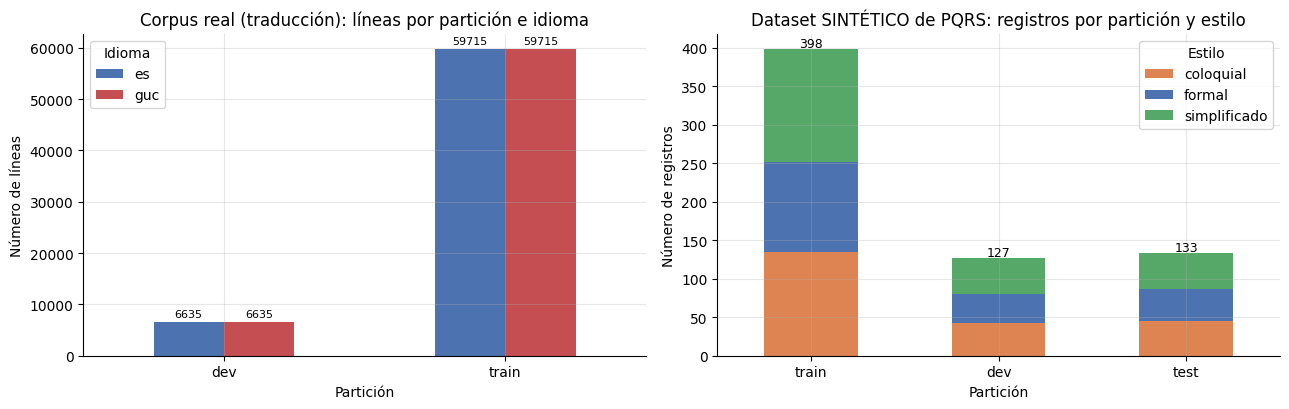

In [ ]:
# ============ Figura 1: registros por partición ============
paneles = 2 if CORPUS_OK else 1
fig, axs = plt.subplots(1, paneles, figsize=(6.5 * paneles, 4.2), squeeze=False)
ax_i = 0
if CORPUS_OK:
    ct = pd.crosstab(df_corpus["particion"], df_corpus["idioma"])
    ct.plot(kind="bar", ax=axs[0][0], color=["#4C72B0", "#C44E52"], rot=0)
    axs[0][0].set_title("Corpus real (traducción): líneas por partición e idioma")
    axs[0][0].set_xlabel("Partición"); axs[0][0].set_ylabel("Número de líneas"); axs[0][0].legend(title="Idioma")
    for c in axs[0][0].containers: axs[0][0].bar_label(c, padding=2, fontsize=8)
    ax_i = 1
ct2 = pd.crosstab(df_pqrs["split"], df_pqrs["style"]).reindex(["train", "dev", "test"])
ct2.plot(kind="bar", stacked=True, ax=axs[0][ax_i], color=[COLORES_ESTILO[c] for c in ct2.columns], rot=0)
axs[0][ax_i].set_title("Dataset SINTÉTICO de PQRS: registros por partición y estilo")
axs[0][ax_i].set_xlabel("Partición"); axs[0][ax_i].set_ylabel("Número de registros"); axs[0][ax_i].legend(title="Estilo")
for i, tot in enumerate(ct2.sum(axis=1)): axs[0][ax_i].text(i, tot + 3, str(int(tot)), ha="center", fontsize=9)
fig.tight_layout(); guardar_fig(fig, "fig1_registros_por_particion.png"); plt.show()
if not CORPUS_OK: print("Nota: panel del corpus omitido (archivos no disponibles).")

Figura guardada: salidas_eda/fig2_distribucion_intenciones.png


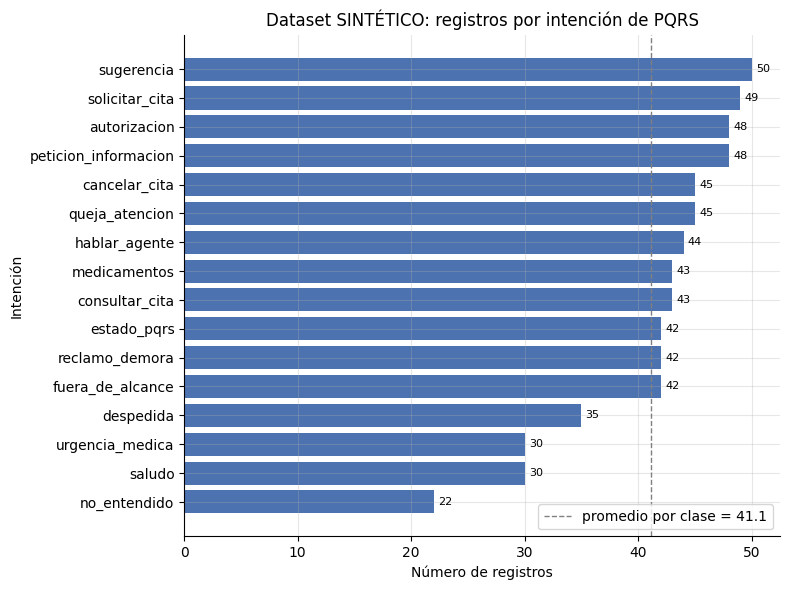

In [ ]:
# ============ Figura 2: distribución de intenciones (sintético) ============
conteo = df_pqrs["intent"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
barras = ax.barh(conteo.index, conteo.values, color="#4C72B0")
ax.axvline(conteo.mean(), color="gray", ls="--", lw=1, label=f"promedio por clase = {conteo.mean():.1f}")
ax.bar_label(barras, padding=3, fontsize=8)
ax.set_title("Dataset SINTÉTICO: registros por intención de PQRS")
ax.set_xlabel("Número de registros"); ax.set_ylabel("Intención"); ax.legend(loc="lower right")
fig.tight_layout(); guardar_fig(fig, "fig2_distribucion_intenciones.png"); plt.show()

Figura guardada: salidas_eda/fig3_distribucion_longitudes.png


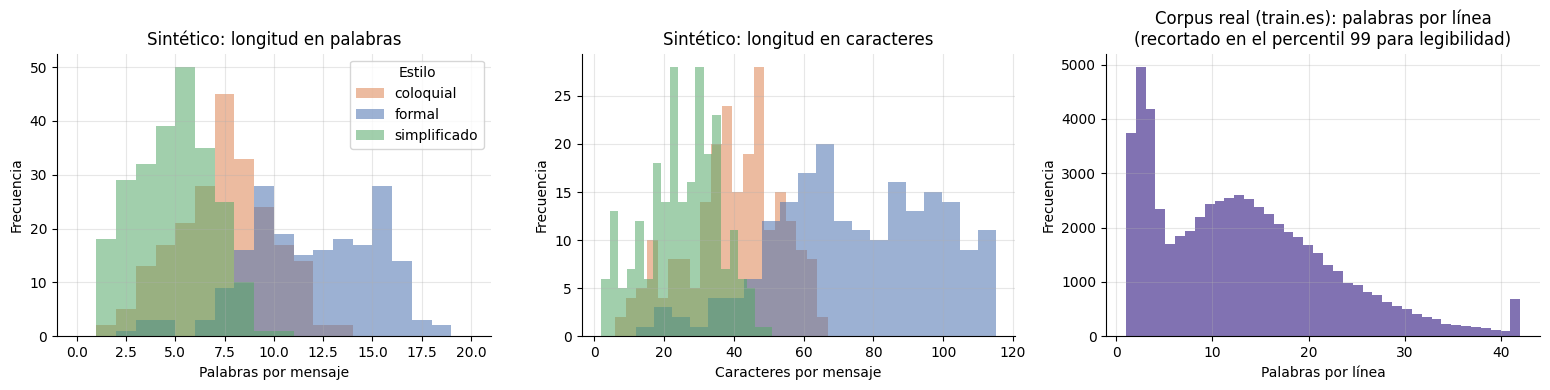

In [ ]:
# ============ Figura 3: distribución de longitudes de mensajes ============
n_pan = 3 if CORPUS_OK else 2
fig, axs = plt.subplots(1, n_pan, figsize=(5.2 * n_pan, 4))
d = df_pqrs.assign(palabras=df_pqrs["text"].map(n_palabras), caracteres=df_pqrs["text"].str.len())
for est, sub in d.groupby("style"):
    axs[0].hist(sub["palabras"], bins=range(0, int(d["palabras"].max()) + 3), alpha=0.55, label=est, color=COLORES_ESTILO[est])
    axs[1].hist(sub["caracteres"], bins=20, alpha=0.55, label=est, color=COLORES_ESTILO[est])
axs[0].set_title("Sintético: longitud en palabras"); axs[0].set_xlabel("Palabras por mensaje"); axs[0].set_ylabel("Frecuencia"); axs[0].legend(title="Estilo")
axs[1].set_title("Sintético: longitud en caracteres"); axs[1].set_xlabel("Caracteres por mensaje"); axs[1].set_ylabel("Frecuencia")
if CORPUS_OK:
    c = corpus_util[(corpus_util.particion == "train") & (corpus_util.idioma == "es")]["texto"].map(n_palabras)
    axs[2].hist(c.clip(upper=c.quantile(0.99)), bins=40, color="#8172B2")
    axs[2].set_title("Corpus real (train.es): palabras por línea\n(recortado en el percentil 99 para legibilidad)")
    axs[2].set_xlabel("Palabras por línea"); axs[2].set_ylabel("Frecuencia")
fig.tight_layout(); guardar_fig(fig, "fig3_distribucion_longitudes.png"); plt.show()

Figura guardada: salidas_eda/fig4_es_vs_wayuunaiki.png


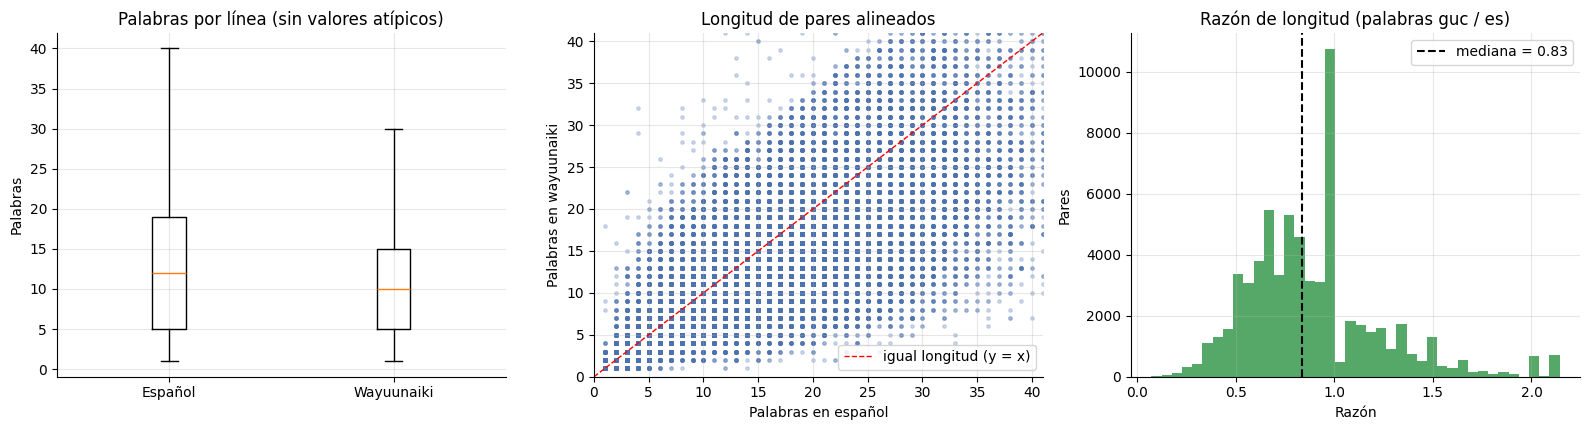

In [ ]:
# ============ Figura 4: español vs wayuunaiki (sólo corpus alineado) ============
if CORPUS_OK and df_par is not None and len(df_par):
    base = df_par[~df_par.vacio_es & ~df_par.vacio_guc]
    fig, axs = plt.subplots(1, 3, figsize=(16, 4.4))
    datos = [base["pal_es"], base["pal_guc"]]
    axs[0].boxplot(datos, tick_labels=["Español", "Wayuunaiki"], showfliers=False)
    axs[0].set_title("Palabras por línea (sin valores atípicos)"); axs[0].set_ylabel("Palabras")
    lim = float(max(base["pal_es"].quantile(.99), base["pal_guc"].quantile(.99)))
    axs[1].scatter(base["pal_es"], base["pal_guc"], s=6, alpha=0.25, color="#4C72B0")
    axs[1].plot([0, lim], [0, lim], "r--", lw=1, label="igual longitud (y = x)")
    axs[1].set_xlim(0, lim); axs[1].set_ylim(0, lim)
    axs[1].set_title("Longitud de pares alineados"); axs[1].set_xlabel("Palabras en español"); axs[1].set_ylabel("Palabras en wayuunaiki"); axs[1].legend()
    r = base["ratio_pal"].dropna()
    axs[2].hist(r.clip(upper=r.quantile(0.99)), bins=40, color="#55A868")
    axs[2].axvline(r.median(), color="k", ls="--", label=f"mediana = {r.median():.2f}")
    axs[2].set_title("Razón de longitud (palabras guc / es)"); axs[2].set_xlabel("Razón"); axs[2].set_ylabel("Pares"); axs[2].legend()
    if not df_par["alineacion_confiable"].all():
        fig.suptitle("⚠ Hay particiones con distinto número de líneas: el emparejamiento por posición no es confiable", color="red")
    fig.tight_layout(); guardar_fig(fig, "fig4_es_vs_wayuunaiki.png"); plt.show()
else:
    print("⚠ Figura 4 omitida: requiere los cuatro archivos paralelos del corpus.")

Figura guardada: salidas_eda/fig5_palabras_por_intencion.png


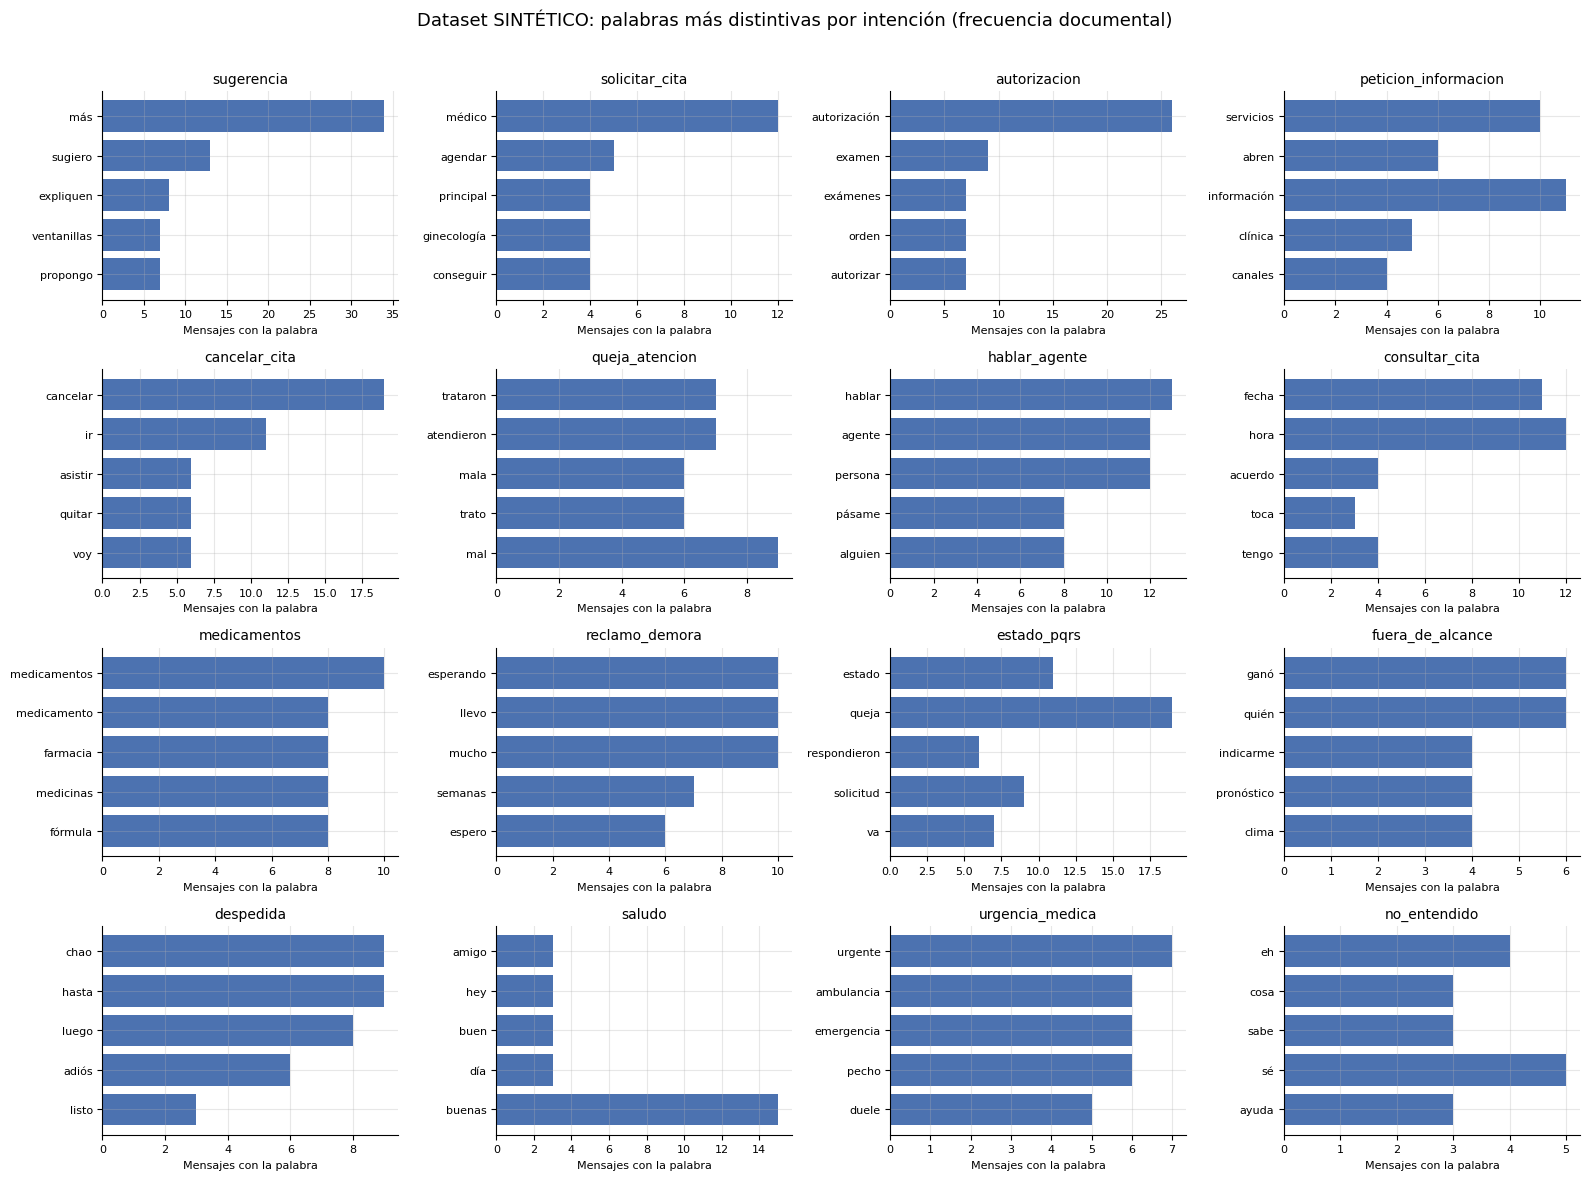

,palabras distintivas (mensajes)
sugerencia,"más(34), sugiero(13), expliquen(8), ventanillas(7), propongo(7)"
solicitar_cita,"médico(12), agendar(5), principal(4), ginecología(4), conseguir(4)"
autorizacion,"autorización(26), examen(9), exámenes(7), orden(7), autorizar(7)"
peticion_informacion,"servicios(10), abren(6), información(11), clínica(5), canales(4)"
cancelar_cita,"cancelar(19), ir(11), asistir(6), quitar(6), voy(6)"
queja_atencion,"trataron(7), atendieron(7), mala(6), trato(6), mal(9)"
hablar_agente,"hablar(13), agente(12), persona(12), pásame(8), alguien(8)"
consultar_cita,"fecha(11), hora(12), acuerdo(4), toca(3), tengo(4)"
medicamentos,"medicamentos(10), medicamento(8), farmacia(8), medicinas(8), fórmula(8)"
reclamo_demora,"esperando(10), llevo(10), mucho(10), semanas(7), espero(6)"


In [ ]:
# ============ Figura 5: palabras relevantes por intención (sintético) ============
# "Relevante" = distintiva: cociente entre la frecuencia documental dentro de la intención y fuera de ella
# (con suavizado). La longitud de la barra es el número de mensajes de la intención que contienen la palabra.
conj = df_pqrs["tokens"].map(set)
def palabras_relevantes(intencion, k=5, min_df=3):
    dentro, fuera = conj[df_pqrs.intent == intencion], conj[df_pqrs.intent != intencion]
    c_in = Counter(w for s in dentro for w in s if w not in STOP_ES)
    c_out = Counter(w for s in fuera for w in s)
    n_in, n_out = len(dentro), len(fuera)
    punt = {w: ((c / n_in) + 0.01) / ((c_out.get(w, 0) / n_out) + 0.01) for w, c in c_in.items() if c >= min_df}
    top = sorted(punt, key=lambda w: (-punt[w], -c_in[w]))[:k]
    return [(w, c_in[w], round(punt[w], 1)) for w in top]

relevantes = {i: palabras_relevantes(i) for i in ORDEN_INT}
fig, axs = plt.subplots(4, 4, figsize=(16, 12))
for ax, intencion in zip(axs.ravel(), ORDEN_INT):
    pares_w = relevantes[intencion][::-1]
    if pares_w:
        ax.barh([w for w, _, _ in pares_w], [c for _, c, _ in pares_w], color="#4C72B0")
    ax.set_title(intencion, fontsize=10); ax.set_xlabel("Mensajes con la palabra", fontsize=8); ax.tick_params(labelsize=8)
fig.suptitle("Dataset SINTÉTICO: palabras más distintivas por intención (frecuencia documental)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.97]); guardar_fig(fig, "fig5_palabras_por_intencion.png"); plt.show()
display(pd.DataFrame({i: ", ".join(f"{w}({c})" for w, c, _ in v) for i, v in relevantes.items()}, index=["palabras distintivas (mensajes)"]).T)

Figura guardada: salidas_eda/fig6_calidad_por_fuente.png


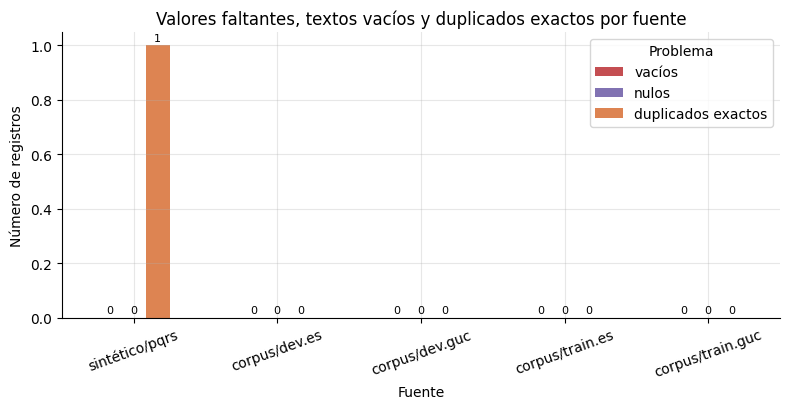

,vacíos,nulos,duplicados exactos
fuente,,,
sintético/pqrs,0,0,1
corpus/dev.es,0,0,0
corpus/dev.guc,0,0,0
corpus/train.es,0,0,0
corpus/train.guc,0,0,0


In [ ]:
# ============ Figura 6: faltantes, vacíos y duplicados por fuente ============
filas = [{"fuente": "sintético/pqrs", "vacíos": int(resumen_sint["vacios"].iloc[0]), "nulos": int(resumen_sint["nulos"].iloc[0]),
          "duplicados exactos": int(resumen_sint["duplicados_exactos"].iloc[0])}]
if CORPUS_OK and resumen_corpus is not None:
    for _, r in resumen_corpus.iterrows():
        filas.append({"fuente": f"corpus/{r['grupo'][0]}.{r['grupo'][1]}", "vacíos": int(r["vacios"]), "nulos": int(r["nulos"]),
                      "duplicados exactos": int(r["duplicados_exactos"])})
cal = pd.DataFrame(filas).set_index("fuente")
fig, ax = plt.subplots(figsize=(max(7, 1.6 * len(cal)), 4.2))
cal.plot(kind="bar", ax=ax, rot=20, color=["#C44E52", "#8172B2", "#DD8452"])
for c in ax.containers: ax.bar_label(c, padding=2, fontsize=8)
ax.set_title("Valores faltantes, textos vacíos y duplicados exactos por fuente")
ax.set_xlabel("Fuente"); ax.set_ylabel("Número de registros"); ax.legend(title="Problema")
fig.tight_layout(); guardar_fig(fig, "fig6_calidad_por_fuente.png"); plt.show()
display(cal)
if not CORPUS_OK: print("Nota: sólo aparece la fuente sintética porque el corpus no está disponible.")

## Sección 8. Análisis textual

**Decisiones de limpieza (documentadas)**

| Decisión | Motivo |
|---|---|
| Minúsculas y normalización Unicode **NFC** | Evita tratar como símbolos distintos una letra acentuada precompuesta y la misma letra formada por «A» + acento combinante. |
| Tokenización por letras Unicode, **apóstrofo interno permitido** | Conserva palabras con saltillo (p. ej. ` ' ` en wayuunaiki) y acentos del español. |
| **Se conservan las negaciones** (`no`, `ni`, `sin`, `nunca`, `tampoco`, `nada`, `nadie`) y «más» | Cambian el sentido: «*no* puedo ir a mi cita» ≠ «puedo ir a mi cita». |
| Lista de palabras vacías **sólo para español** y mínima | No existe una lista validada de palabras vacías para wayuunaiki; **no se inventa**. Sus frecuencias se muestran sin filtrar. |
| No se aplica *stemming* ni corrección ortográfica | Podría alterar formas en wayuunaiki y no es necesario para un EDA. |

**Interpretación de n-gramas.** Un *bigrama* es un par de palabras consecutivas y un *trigrama* una terna. Los n-gramas frecuentes revelan expresiones fijas («mi cita», «por favor») y plantillas repetidas; si unos pocos n-gramas concentran gran parte del corpus, el modelo podría memorizar plantillas en lugar de generalizar.

In [ ]:
# ============ Sección 8a: frecuencias de palabras y n-gramas ============
def ngramas(tokens, n):
    return zip(*[tokens[i:] for i in range(n)])

def top_ngramas(textos, n=1, k=15, filtrar_stop=False):
    c = Counter()
    for t in textos:
        tk = tokenizar(t)
        if n == 1:
            c.update(w for w in tk if not (filtrar_stop and w in STOP_ES))
        else:
            c.update(" ".join(g) for g in ngramas(tk, n))
    total = sum(c.values()) or 1
    return pd.DataFrame([(g, f, round(100 * f / total, 2)) for g, f in c.most_common(k)], columns=["n-grama", "frecuencia", "% de n-gramas"])

print("— SINTÉTICO (ficticio): palabras más frecuentes (sin palabras vacías; negaciones conservadas) —")
display(top_ngramas(df_pqrs["text"], 1, 15, True))
print("— SINTÉTICO: bigramas —");  display(top_ngramas(df_pqrs["text"], 2, 12))
print("— SINTÉTICO: trigramas —"); display(top_ngramas(df_pqrs["text"], 3, 10))

if CORPUS_OK:
    es_tr = corpus_util[(corpus_util.particion == "train") & (corpus_util.idioma == "es")]["texto"]
    gu_tr = corpus_util[(corpus_util.particion == "train") & (corpus_util.idioma == "guc")]["texto"]
    print("\n— CORPUS train.es: palabras más frecuentes (sin palabras vacías) —"); display(top_ngramas(es_tr, 1, 20, True))
    print("— CORPUS train.es: bigramas —"); display(top_ngramas(es_tr, 2, 15))
    print("— CORPUS train.guc (wayuunaiki): palabras más frecuentes, SIN filtrar (no hay lista de vacías validada) —"); display(top_ngramas(gu_tr, 1, 20))
    print("— CORPUS train.guc: bigramas —"); display(top_ngramas(gu_tr, 2, 15))
    voc_es, voc_gu = {w for t in es_tr for w in tokenizar(t)}, {w for t in gu_tr for w in tokenizar(t)}
    print(f"\nVocabulario distinto en train: español={len(voc_es):,}, wayuunaiki={len(voc_gu):,}")
    print("Cobertura: palabras de PQRS sintético (español) presentes en el vocabulario es del corpus:",
          f"{100*len({w for ts in df_pqrs['tokens'] for w in ts} & voc_es)/len({w for ts in df_pqrs['tokens'] for w in ts}):.1f}%")
else:
    print("\n⚠ Análisis textual del corpus omitido: archivos no disponibles.")

— SINTÉTICO (ficticio): palabras más frecuentes (sin palabras vacías; negaciones conservadas) —


,n-grama,frecuencia,% de n-gramas
0,gracias,148,4.94
1,cita,134,4.47
2,hola,101,3.37
3,favor,94,3.14
4,atención,83,2.77
5,buenas,73,2.43
6,no,71,2.37
7,solicito,49,1.63
8,días,43,1.43
9,respuesta,40,1.33


— SINTÉTICO: bigramas —


,n-grama,frecuencia,% de n-gramas
0,por favor,94,2.24
1,mi cita,56,1.33
2,gracias por,48,1.14
3,por su,48,1.14
4,su atención,48,1.14
5,de mi,45,1.07
6,agradezco su,38,0.90
7,su pronta,37,0.88
8,pronta respuesta,37,0.88
9,buenos días,35,0.83


— SINTÉTICO: trigramas —


...

— CORPUS train.guc (wayuunaiki): palabras más frecuentes, SIN filtrar (no hay lista de vacías validada) —


,n-grama,frecuencia,% de n-gramas
0,tü,35818,5.25
1,na,15520,2.28
2,süpüla,11782,1.73
3,sünain,11176,1.64
4,wayuu,10121,1.48
5,kasa,9429,1.38
6,chi,8763,1.29
7,je'waa,7963,1.17
8,wanee,7862,1.15
9,otta,7168,1.05


— CORPUS train.guc: bigramas —


,n-grama,frecuencia,% de n-gramas
0,tü kasa,2997,0.48
1,tü wiwüliakat,2814,0.45
2,sünain tü,1926,0.31
3,sulu'u tü,1492,0.24
4,wanee wayuu,1443,0.23
5,na wayuu,1437,0.23
6,namüin na,1423,0.23
7,wanaa sümaa,1418,0.23
8,nümüin je'waa,1375,0.22
9,wanee kasa,1296,0.21



Vocabulario distinto en train: español=31,182, wayuunaiki=49,880
Cobertura: palabras de PQRS sintético (español) presentes en el vocabulario es del corpus: 82.6%


— Mensajes sintéticos con negación, por intención —


,con_negación,proporción
intent,,
cancelar_cita,23,0.511
reclamo_demora,14,0.333
medicamentos,10,0.233
autorizacion,7,0.146
queja_atencion,7,0.156
urgencia_medica,7,0.233
no_entendido,6,0.273
hablar_agente,5,0.114


Total con negación: 86 de 658 (13.1%).
Nota: detección léxica; incluye usos que no son negación semántica (p. ej. la muletilla «¿no?»).
Ejemplos (si se eliminara «no», estos mensajes cambiarían de sentido):


,text,intent
609,Me pidieron una autorización y no sé cómo sacarla.,autorizacion
4,Hola. Ya no quiero la cita!,cancelar_cita
573,Llevo un mes esperando y nada que me atienden.,reclamo_demora
175,"buenas, todavía no me responden y ya pasaron semanas. por favor",reclamo_demora
45,no hay pastillas en la farmacia. por favor,medicamentos
436,"Podrían poner más ventanillas, ¿no?",sugerencia



— Pares de intenciones con mayor solapamiento de vocabulario —


,intención_A,intención_B,jaccard,palabras_compartidas (muestra)
20,solicitar_cita,consultar_cita,0.347,"[especialista, agradezco, respuesta, solicito, necesito, atención]"
56,cancelar_cita,consultar_cita,0.329,"[especialista, programada, agradezco, respuesta, asignada, solicito]"
17,solicitar_cita,cancelar_cita,0.282,"[especialista, agradezco, respuesta, solicito, atención, requiero]"
15,solicitar_cita,autorizacion,0.276,"[especialista, agradezco, respuesta, solicito, necesito, atención]"
45,peticion_informacion,consultar_cita,0.276,"[agradezco, respuesta, solicito, atención, cordial, conocer]"
33,autorizacion,consultar_cita,0.273,"[especialista, agradezco, respuesta, solicito, necesito, atención]"
46,peticion_informacion,medicamentos,0.270,"[información, agradezco, respuesta, solicito, atención, requiero]"
32,autorizacion,hablar_agente,0.269,"[agradezco, respuesta, solicito, necesito, atención, requiero]"


Nota: parte del solapamiento proviene de prefijos/sufijos de cortesía añadidos por el generador y no de la semántica de la intención.
Figura guardada: salidas_eda/fig8_solapamiento_intenciones.png


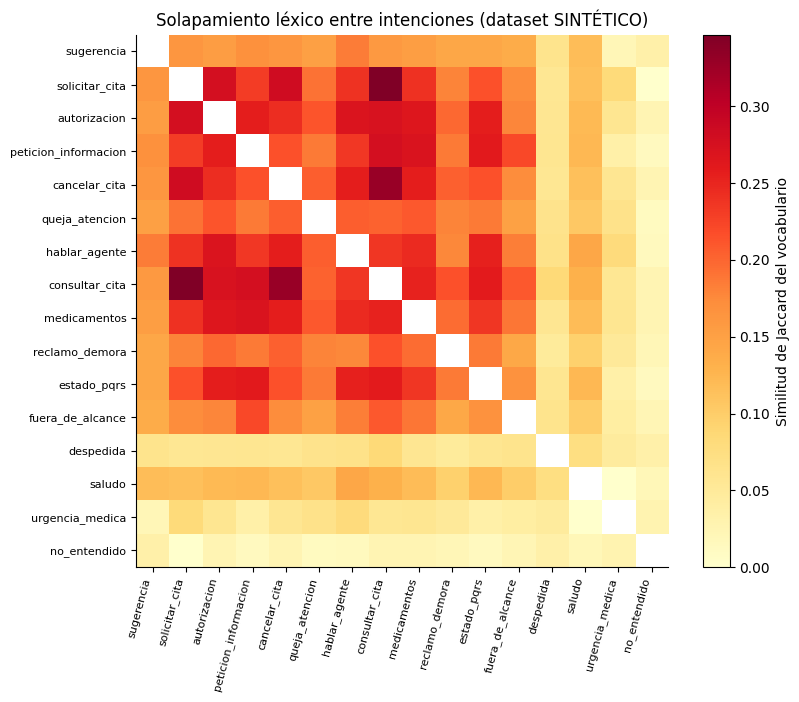

In [ ]:
# ============ Sección 8b: negaciones y solapamiento léxico entre intenciones ============
df_pqrs["tiene_negacion"] = df_pqrs["tokens"].map(lambda ts: any(t in NEGACIONES for t in ts))
neg_por_int = df_pqrs.groupby("intent")["tiene_negacion"].agg(["sum", "mean"]).rename(columns={"sum": "con_negación", "mean": "proporción"}).round(3)
print("— Mensajes sintéticos con negación, por intención —")
display(neg_por_int.sort_values("con_negación", ascending=False).head(8))
PCT_NEG = 100 * df_pqrs["tiene_negacion"].mean()
print(f"Total con negación: {int(df_pqrs['tiene_negacion'].sum())} de {len(df_pqrs)} ({PCT_NEG:.1f}%).")
print("Nota: detección léxica; incluye usos que no son negación semántica (p. ej. la muletilla «¿no?»).")
print("Ejemplos (si se eliminara «no», estos mensajes cambiarían de sentido):")
display(df_pqrs[df_pqrs["tiene_negacion"]].sample(min(6, int(df_pqrs["tiene_negacion"].sum())), random_state=SEMILLA)[["text", "intent"]])

# Solapamiento léxico: Jaccard entre vocabularios de contenido de cada par de intenciones
vocab = {i: {w for ts in df_pqrs.loc[df_pqrs.intent == i, "tokens"] for w in ts if w not in STOP_ES} for i in ORDEN_INT}
pares_j = []
for a in range(len(ORDEN_INT)):
    for b in range(a + 1, len(ORDEN_INT)):
        A, B = vocab[ORDEN_INT[a]], vocab[ORDEN_INT[b]]
        pares_j.append((ORDEN_INT[a], ORDEN_INT[b], len(A & B) / len(A | B), sorted(A & B, key=len, reverse=True)[:6]))
tabla_j = pd.DataFrame(pares_j, columns=["intención_A", "intención_B", "jaccard", "palabras_compartidas (muestra)"]).sort_values("jaccard", ascending=False)
print("\n— Pares de intenciones con mayor solapamiento de vocabulario —")
display(tabla_j.head(8).round(3))
print("Nota: parte del solapamiento proviene de prefijos/sufijos de cortesía añadidos por el generador y no de la semántica de la intención.")

M = np.zeros((len(ORDEN_INT),) * 2)
for a, b, j, _ in pares_j:
    M[ORDEN_INT.index(a), ORDEN_INT.index(b)] = M[ORDEN_INT.index(b), ORDEN_INT.index(a)] = j
np.fill_diagonal(M, np.nan)
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(M, cmap="YlOrRd"); fig.colorbar(im, ax=ax, label="Similitud de Jaccard del vocabulario")
ax.set_xticks(range(len(ORDEN_INT))); ax.set_xticklabels(ORDEN_INT, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(len(ORDEN_INT))); ax.set_yticklabels(ORDEN_INT, fontsize=8)
ax.set_title("Solapamiento léxico entre intenciones (dataset SINTÉTICO)"); ax.grid(False)
fig.tight_layout(); guardar_fig(fig, "fig8_solapamiento_intenciones.png"); plt.show()
TOP_SOLAP = tabla_j.head(3)

## Sección 9. Hallazgos y limitaciones

Las conclusiones de esta sección **se redactan por código a partir de las variables calculadas arriba**: si cambian los datos (por ejemplo, al cargar el corpus completo en Colab), el texto se actualiza con ellos. Se separan siempre los hallazgos del **corpus de traducción** de los del **dataset sintético**.

In [ ]:
# ============ Sección 9: hallazgos generados a partir de los resultados ============
L = []
L.append("### 9.1 Hallazgos del corpus de traducción español–wayuunaiki (datos reales)")
if CORPUS_OK:
    tot = len(df_corpus)
    L.append(f"- Se cargaron **{tot:,} líneas** en 4 archivos (train/dev × es/guc); versión identificada por huella SHA-256 en la Sección 3.")
    for _, r in resumen_alin.iterrows():
        estado = "coinciden" if r["mismo_numero_de_lineas"] else f"**NO coinciden** (diferencia {int(r['diferencia'])})"
        L.append(f"- Partición `{r['particion']}`: {int(r['lineas_es']):,} líneas en español y {int(r['lineas_guc']):,} en wayuunaiki; los totales {estado}.")
    vac = int(resumen_corpus["vacios"].sum()); dup_tot = int(resumen_corpus["duplicados_exactos"].sum())
    L.append(f"- Textos vacíos: **{vac}**; duplicados exactos (dentro de cada archivo): **{dup_tot}**; textos presentes a la vez en train y dev: es={FUGA_CORPUS['es']}, guc={FUGA_CORPUS['guc']}.")
    prob_cod = int(resumen_corpus[["caracter_reemplazo", "mojibake", "control", "no_nfc"]].sum().sum())
    L.append(f"- Señales de problemas de codificación/normalización (reemplazo �, mojibake, control o no-NFC): **{prob_cod}** casos marcados.")
    L.append(f"- Posibles datos personales marcados por patrón (URL, correo, 7+ dígitos): **{int(resumen_corpus['posible_dato_personal'].sum())}** (requieren revisión manual).")
    if len(ok):
        L.append(f"- Razón de longitud wayuunaiki/español en palabras: mediana **{ok.ratio_pal.median():.2f}**; correlación de longitudes **{ok[['pal_es','pal_guc']].corr().iloc[0,1]:.2f}**; pares con razón extrema: **{int(ok.ratio_extremo.sum())}** ({100*ok.ratio_extremo.mean():.2f}%).")
    if est_corpus is not None:
        m_es = est_corpus.loc[("('train', 'es')", "palabras"), "mediana"]; m_gu = est_corpus.loc[("('train', 'guc')", "palabras"), "mediana"]
        L.append(f"- Longitud mediana en `train`: **{m_es:.0f}** palabras (español) y **{m_gu:.0f}** (wayuunaiki).")
    L.append("- **Interpretación:** es un corpus de *frases de traducción*, no de mensajes de usuarios ni de PQRS; sirve como referencia léxica y de formato, no para entrenar el clasificador de intenciones.")
else:
    L.append("- **No se pudo cargar el corpus en esta ejecución** (ver tabla de la Sección 3), por lo que **no se reporta ningún hallazgo sobre él**. Ejecute el notebook con los archivos disponibles (ver `README_EDA.md`) para completar esta subsección.")
if df_dicc is not None:
    L.append(f"- Diccionario: {len(df_dicc):,} filas × {df_dicc.shape[1]} columnas (columnas interpretadas: {COL_ES_DICC!r} / {COL_GUC_DICC!r}).")

L.append("\n### 9.2 Hallazgos del dataset sintético de PQRS (ficticio; no refleja PQRS reales)")
n = len(df_pqrs); c_est = df_pqrs["style"].value_counts(normalize=True).mul(100).round(1)
L.append(f"- {n} registros, {df_pqrs['intent'].nunique()} intenciones y 3 estilos (formal {c_est['formal']}%, coloquial {c_est['coloquial']}%, simplificado {c_est['simplificado']}%).")
L.append(f"- Clase mayor `{dist_int.index[0]}` ({dist_int.iloc[0]}) vs. clase menor `{dist_int.index[-1]}` ({dist_int.iloc[-1]}): razón de desbalance **{RATIO_DESB:.2f}**, entropía normalizada **{ENTROPIA_NORM:.3f}**. Las intenciones sin prefijos/sufijos (`saludo`, `despedida`, `urgencia_medica`, `no_entendido`) tienen menos variantes.")
L.append(f"- Duplicados exactos: **{int(resumen_sint['duplicados_exactos'].iloc[0])}**; textos normalizados con etiquetas en conflicto: **{CONFLICTOS_ETIQUETA}**.")
L.append(f"- Longitud media en palabras — formal {est_estilo.loc[('formal','palabras'),'media']:.1f}, coloquial {est_estilo.loc[('coloquial','palabras'),'media']:.1f}, simplificado {est_estilo.loc[('simplificado','palabras'),'media']:.1f} (diferencia atribuible al diseño del generador).")
L.append(f"- Fuga entre particiones: **{FUGA_AGRUPADA:.1f}%** con partición por plantilla vs. **{FUGA_ALEATORIA:.1f}%** con partición aleatoria ingenua (filas de dev/test cuya plantilla aparece en train).")
L.append(f"- Negaciones: **{PCT_NEG:.1f}%** de los mensajes contienen una; eliminarlas como «palabras vacías» alteraría el significado de esas solicitudes.")
top = "; ".join(f"`{r['intención_A']}`–`{r['intención_B']}` (J={r['jaccard']:.2f})" for _, r in TOP_SOLAP.iterrows())
L.append(f"- Mayor solapamiento léxico entre etiquetas: {top}. Conviene definir guías de anotación para distinguir, p. ej., *queja* vs. *reclamo por demora* o *autorización* vs. *medicamentos*.")

L.append("\n### 9.3 Recomendaciones para el futuro entrenamiento del clasificador")
L += ["1. **Aumentar y equilibrar** los ejemplos por intención con mensajes más diversos que las plantillas actuales; vigilar `no_entendido` y `urgencia_medica`, donde el costo del error es mayor.",
      "2. **Revisar solapamientos** entre etiquetas (tabla de Jaccard y conflictos de etiqueta) y redactar una guía de anotación con ejemplos límite.",
      "3. **Separar entrenamiento, validación y prueba** *antes* de cualquier ajuste, agrupando por plantilla/hablante/radicado para evitar fuga.",
      "4. **Prevenir duplicados y filtraciones**: deduplicar por texto normalizado dentro y entre particiones y registrar la evidencia.",
      "5. **Validar lingüísticamente** todo contenido en wayuunaiki con hablantes competentes antes de usarlo; no generar traducciones con modelos sin revisión humana.",
      "6. **Obtener datos representativos** (PQRS reales anonimizadas) con autorización institucional, consentimiento y garantías de privacidad (minimización, anonimización, control de acceso).",
      "7. **Tratar `urgencia_medica` como regla de seguridad**: la detección debe priorizar recall y escalar a un humano; no depender sólo de un clasificador entrenado con datos sintéticos.",
      "8. Mantener las **negaciones** en el preprocesamiento y evaluar con métricas por clase (no sólo exactitud global)."]

L.append("\n### 9.4 Limitaciones")
L += ["- El dataset sintético es **ficticio y generado por plantillas**: su léxico es más regular que el de usuarios reales; ninguna distribución aquí describe PQRS reales.",
      "- No se incluye wayuunaiki en el dataset sintético (`wayuu_status` = pendiente de validación).",
      "- El corpus de traducción no está etiquetado por intención; su utilidad directa para PQRS es limitada.",
      "- La alineación se evalúa por posición de línea; una desalineación sistemática sólo puede confirmarse con revisión por hablantes.",
      "- Los criterios de anomalía (IQR×3, z robusto 3.5, patrones de dato personal) son heurísticos y generan falsos positivos/negativos.",
      "- No se entrenó ni evaluó ningún modelo: **no se reporta precisión alguna**."]
mostrar_md("\n".join(L))

### 9.1 Hallazgos del corpus de traducción español–wayuunaiki (datos reales)
- Se cargaron **132,700 líneas** en 4 archivos (train/dev × es/guc); versión identificada por huella SHA-256 en la Sección 3.
- Partición `train`: 59,715 líneas en español y 59,715 en wayuunaiki; los totales coinciden.
- Partición `dev`: 6,635 líneas en español y 6,635 en wayuunaiki; los totales coinciden.
- Textos vacíos: **0**; duplicados exactos (dentro de cada archivo): **0**; textos presentes a la vez en train y dev: es=0, guc=0.
- Señales de problemas de codificación/normalización (reemplazo �, mojibake, control o no-NFC): **0** casos marcados.
- Posibles datos personales marcados por patrón (URL, correo, 7+ dígitos): **0** (requieren revisión manual).
- Razón de longitud wayuunaiki/español en palabras: mediana **0.83**; correlación de longitudes **0.92**; pares con razón extrema: **702** (1.06%).
- Longitud mediana en `train`: **12** palabras (español) y **10** (wayuunaiki).
- **Interpretación:** es un corpus de *frases de traducción*, no de mensajes de usuarios ni de PQRS; sirve como referencia léxica y de formato, no para entrenar el clasificador de intenciones.
- Diccionario: 29,246 filas × 2 columnas (columnas interpretadas: 'spa' / 'guc').

### 9.2 Hallazgos del dataset sintético de PQRS (ficticio; no refleja PQRS reales)
- 658 registros, 16 intenciones y 3 estilos (formal 29.6%, coloquial 33.9%, simplificado 36.5%).
- Clase mayor `sugerencia` (50) vs. clase menor `no_entendido` (22): razón de desbalance **2.27**, entropía normalizada **0.993**. Las intenciones sin prefijos/sufijos (`saludo`, `despedida`, `urgencia_medica`, `no_entendido`) tienen menos variantes.
- Duplicados exactos: **1**; textos normalizados con etiquetas en conflicto: **0**.
- Longitud media en palabras — formal 11.5, coloquial 7.0, simplificado 4.4 (diferencia atribuible al diseño del generador).
- Fuga entre particiones: **0.0%** con partición por plantilla vs. **79.7%** con partición aleatoria ingenua (filas de dev/test cuya plantilla aparece en train).
- Negaciones: **13.1%** de los mensajes contienen una; eliminarlas como «palabras vacías» alteraría el significado de esas solicitudes.
- Mayor solapamiento léxico entre etiquetas: `solicitar_cita`–`consultar_cita` (J=0.35); `cancelar_cita`–`consultar_cita` (J=0.33); `solicitar_cita`–`cancelar_cita` (J=0.28). Conviene definir guías de anotación para distinguir, p. ej., *queja* vs. *reclamo por demora* o *autorización* vs. *medicamentos*.

### 9.3 Recomendaciones para el futuro entrenamiento del clasificador
1. **Aumentar y equilibrar** los ejemplos por intención con mensajes más diversos que las plantillas actuales; vigilar `no_entendido` y `urgencia_medica`, donde el costo del error es mayor.
2. **Revisar solapamientos** entre etiquetas (tabla de Jaccard y conflictos de etiqueta) y redactar una guía de anotación con ejemplos límite.
3. **Separar entrenamiento, validación y prueba** *antes* de cualquier ajuste, agrupando por plantilla/hablante/radicado para evitar fuga.
4. **Prevenir duplicados y filtraciones**: deduplicar por texto normalizado dentro y entre particiones y registrar la evidencia.
5. **Validar lingüísticamente** todo contenido en wayuunaiki con hablantes competentes antes de usarlo; no generar traducciones con modelos sin revisión humana.
6. **Obtener datos representativos** (PQRS reales anonimizadas) con autorización institucional, consentimiento y garantías de privacidad (minimización, anonimización, control de acceso).
7. **Tratar `urgencia_medica` como regla de seguridad**: la detección debe priorizar recall y escalar a un humano; no depender sólo de un clasificador entrenado con datos sintéticos.
8. Mantener las **negaciones** en el preprocesamiento y evaluar con métricas por clase (no sólo exactitud global).

### 9.4 Limitaciones
- El dataset sintético es **ficticio y generado por plantillas**: su léxico es más regular que el de usuarios reales; ninguna distribución aquí describe PQRS reales.
- No se incluye wayuunaiki en el dataset sintético (`wayuu_status` = pendiente de validación).
- El corpus de traducción no está etiquetado por intención; su utilidad directa para PQRS es limitada.
- La alineación se evalúa por posición de línea; una desalineación sistemática sólo puede confirmarse con revisión por hablantes.
- Los criterios de anomalía (IQR×3, z robusto 3.5, patrones de dato personal) son heurísticos y generan falsos positivos/negativos.
- No se entrenó ni evaluó ningún modelo: **no se reporta precisión alguna**.

## Sección 10. Conclusión académica

*(Texto base para la sección de análisis exploratorio de datos del informe de la Fase 1. Revise y ajuste las cifras con la ejecución final del equipo.)*

In [ ]:
# ============ Sección 10: conclusión académica (cifras tomadas de las variables calculadas) ============
if CORPUS_OK:
    parte_corpus = (f"Se examinó el corpus de traducción español–wayuunaiki del repositorio RLTranslator ({len(df_corpus):,} líneas en las particiones "
                    f"train y dev), identificado por huella SHA-256. Se verificaron vacíos, duplicados, codificación, alineación por posición y razón de longitud entre idiomas; "
                    f"las evidencias de los problemas encontrados se conservan en `salidas_eda/evidencia_calidad.csv` sin eliminar registros.")
else:
    parte_corpus = ("En esta ejecución no se dispuso de los archivos del corpus de traducción español–wayuunaiki, por lo que no se reportan estadísticas "
                    "sobre él; el notebook queda preparado para calcularlas en cuanto los archivos estén presentes.")
conclusion = f"""
**Conclusión.** El análisis exploratorio de la Fase 1 evaluó dos tipos de fuentes con propósitos distintos. {parte_corpus}
Dicho corpus es un recurso de referencia lingüística y no contiene PQRS etiquetadas.

Para demostrar las técnicas de análisis de clasificación de intenciones se construyó un dataset **sintético y ficticio** de {len(df_pqrs)} mensajes, {df_pqrs['intent'].nunique()} intenciones y tres estilos
(formal, coloquial y simplificado). Su distribución presenta un desbalance {'moderado' if RATIO_DESB <= 3 else 'marcado'} (razón entre la clase mayor y la menor: {RATIO_DESB:.2f}), y **no representa la distribución de PQRS reales** de una institución de salud.
El análisis mostró que las negaciones están presentes en el {PCT_NEG:.1f}% de los mensajes y deben conservarse en el preprocesamiento, que existen pares de intenciones con vocabulario solapado
y que una partición aleatoria ingenua produciría {FUGA_ALEATORIA:.1f}% de fuga por plantilla frente a {FUGA_AGRUPADA:.1f}% con partición por plantilla.

Como siguiente paso se recomienda reunir ejemplos reales anonimizados con autorización, validar con hablantes el contenido en wayuunaiki y definir guías de anotación.
**Este trabajo no entrena ningún clasificador ni reporta precisión alguna: su alcance es exclusivamente exploratorio.**
"""
mostrar_md(conclusion)


**Conclusión.** El análisis exploratorio de la Fase 1 evaluó dos tipos de fuentes con propósitos distintos. Se examinó el corpus de traducción español–wayuunaiki del repositorio RLTranslator (132,700 líneas en las particiones train y dev), identificado por huella SHA-256. Se verificaron vacíos, duplicados, codificación, alineación por posición y razón de longitud entre idiomas; las evidencias de los problemas encontrados se conservan en `salidas_eda/evidencia_calidad.csv` sin eliminar registros.
Dicho corpus es un recurso de referencia lingüística y no contiene PQRS etiquetadas.

Para demostrar las técnicas de análisis de clasificación de intenciones se construyó un dataset **sintético y ficticio** de 658 mensajes, 16 intenciones y tres estilos
(formal, coloquial y simplificado). Su distribución presenta un desbalance moderado (razón entre la clase mayor y la menor: 2.27), y **no representa la distribución de PQRS reales** de una institución de salud.
El análisis mostró que las negaciones están presentes en el 13.1% de los mensajes y deben conservarse en el preprocesamiento, que existen pares de intenciones con vocabulario solapado
y que una partición aleatoria ingenua produciría 79.7% de fuga por plantilla frente a 0.0% con partición por plantilla.

Como siguiente paso se recomienda reunir ejemplos reales anonimizados con autorización, validar con hablantes el contenido en wayuunaiki y definir guías de anotación.
**Este trabajo no entrena ningún clasificador ni reporta precisión alguna: su alcance es exclusivamente exploratorio.**


### Verificaciones automáticas del notebook

Pruebas internas que se ejecutan con los datos cargados. Las que dependen del corpus se marcan como *omitidas* cuando los archivos no están disponibles (no se cuentan como aprobadas).

In [ ]:
# ============ Verificaciones automáticas ============
verif = []
def chequeo(nombre, condicion, omitida=False):
    verif.append({"verificación": nombre, "resultado": "OMITIDA (datos no disponibles)" if omitida else ("OK" if condicion else "FALLA")})

COLS_MIN = {"id", "text", "intent", "language", "style", "source"}
INT_REQ = {"consultar_cita", "solicitar_cita", "cancelar_cita", "medicamentos", "autorizacion", "queja_atencion", "reclamo_demora",
           "peticion_informacion", "sugerencia", "estado_pqrs", "saludo", "despedida", "urgencia_medica", "hablar_agente",
           "fuera_de_alcance", "no_entendido"}
chequeo("Dataset sintético con columnas mínimas (id, text, intent, language, style, source)", COLS_MIN <= set(df_pqrs.columns))
chequeo("Las 16 intenciones requeridas están presentes (y no hay otras)", set(df_pqrs["intent"]) == INT_REQ)
chequeo("Identificadores únicos", df_pqrs["id"].is_unique)
chequeo("Sin textos nulos ni vacíos en el sintético", (df_pqrs["text"].notna() & (df_pqrs["text"].str.strip() != "")).all())
chequeo("Sin patrones de dato personal (URL/correo/7+ dígitos) en el sintético", not banderas_texto(df_pqrs["text"])["posible_dato_personal"].any())
chequeo("Todo el sintético está en español y wayuunaiki marcado como pendiente", (df_pqrs["language"] == "es").all() and (df_pqrs["wayuu_status"] == "no_incluida_pendiente_validacion").all())
chequeo("Partición por plantilla sin fuga de plantillas a dev/test", FUGA_AGRUPADA == 0)
df_relee = pd.read_csv(DATA_DIR / "pqrs_sintetico.csv")
chequeo("CSV guardado idéntico al regenerado con la misma semilla", df_relee.equals(generar_dataset_pqrs(SEMILLA)))
chequeo("Archivo de evidencia de calidad escrito", (OUT_DIR / "evidencia_calidad.csv").is_file())
chequeo("Ningún registro del corpus fue eliminado (líneas en memoria = líneas leídas)", CORPUS_OK and len(df_corpus) == sum(len(df_corpus[(df_corpus.particion == a) & (df_corpus.idioma == b)]) for a in ("train", "dev") for b in ("es", "guc")), omitida=not CORPUS_OK)
display(pd.DataFrame(verif))
FALLAS = [v for v in verif if v["resultado"] == "FALLA"]
print("Resultado global:", "TODAS LAS VERIFICACIONES EJECUTADAS PASARON" if not FALLAS else f"{len(FALLAS)} verificación(es) con FALLA")

,verificación,resultado
0,"Dataset sintético con columnas mínimas (id, text, intent, language, style, source)",OK
1,Las 16 intenciones requeridas están presentes (y no hay otras),OK
2,Identificadores únicos,OK
3,Sin textos nulos ni vacíos en el sintético,OK
4,Sin patrones de dato personal (URL/correo/7+ dígitos) en el sintético,OK
5,Todo el sintético está en español y wayuunaiki marcado como pendiente,OK
6,Partición por plantilla sin fuga de plantillas a dev/test,OK
7,CSV guardado idéntico al regenerado con la misma semilla,OK
8,Archivo de evidencia de calidad escrito,OK
9,Ningún registro del corpus fue eliminado (líneas en memoria = líneas leídas),OK


Resultado global: TODAS LAS VERIFICACIONES EJECUTADAS PASARON


### Acciones que requieren ejecución por parte del equipo

1. Ejecutar este notebook con acceso a Internet (o con los 5 archivos en `datos_manuales/`) para obtener las estadísticas **reales** del corpus (Secciones 4–9).
2. Confirmar con `df_registro` el formato real de cada archivo (¿una columna? ¿encabezado? ¿comillas?) y la **licencia** del repositorio.
3. Revisar `salidas_eda/evidencia_calidad.csv` y decidir, con criterio documentado, qué registros corregir o excluir en la Fase 2.
4. Solicitar a hablantes competentes de wayuunaiki la validación de cualquier texto en esa lengua que se incorpore al dataset de PQRS.
5. Reemplazar el dataset sintético por datos reales anonimizados cuando exista autorización institucional.